In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.linear_model import LinearRegression
from statsmodels.tsa.api import ExponentialSmoothing,SimpleExpSmoothing,Holt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('./gold_monthly_csv.csv',parse_dates=['Date'])
# df.info()

In [3]:
date=pd.date_range(start='1/1/1950',end='8/1/2020',freq='M')
date

DatetimeIndex(['1950-01-31', '1950-02-28', '1950-03-31', '1950-04-30',
               '1950-05-31', '1950-06-30', '1950-07-31', '1950-08-31',
               '1950-09-30', '1950-10-31',
               ...
               '2019-10-31', '2019-11-30', '2019-12-31', '2020-01-31',
               '2020-02-29', '2020-03-31', '2020-04-30', '2020-05-31',
               '2020-06-30', '2020-07-31'],
              dtype='datetime64[ns]', length=847, freq='ME')

In [4]:
df['Month']=date
df.drop('Date',axis=1,inplace=True)
df=df.set_index('Month')
df.head()

,Price
Month,
1950-01-31,34.72
1950-02-28,34.72
1950-03-31,34.72
1950-04-30,34.72
1950-05-31,34.72


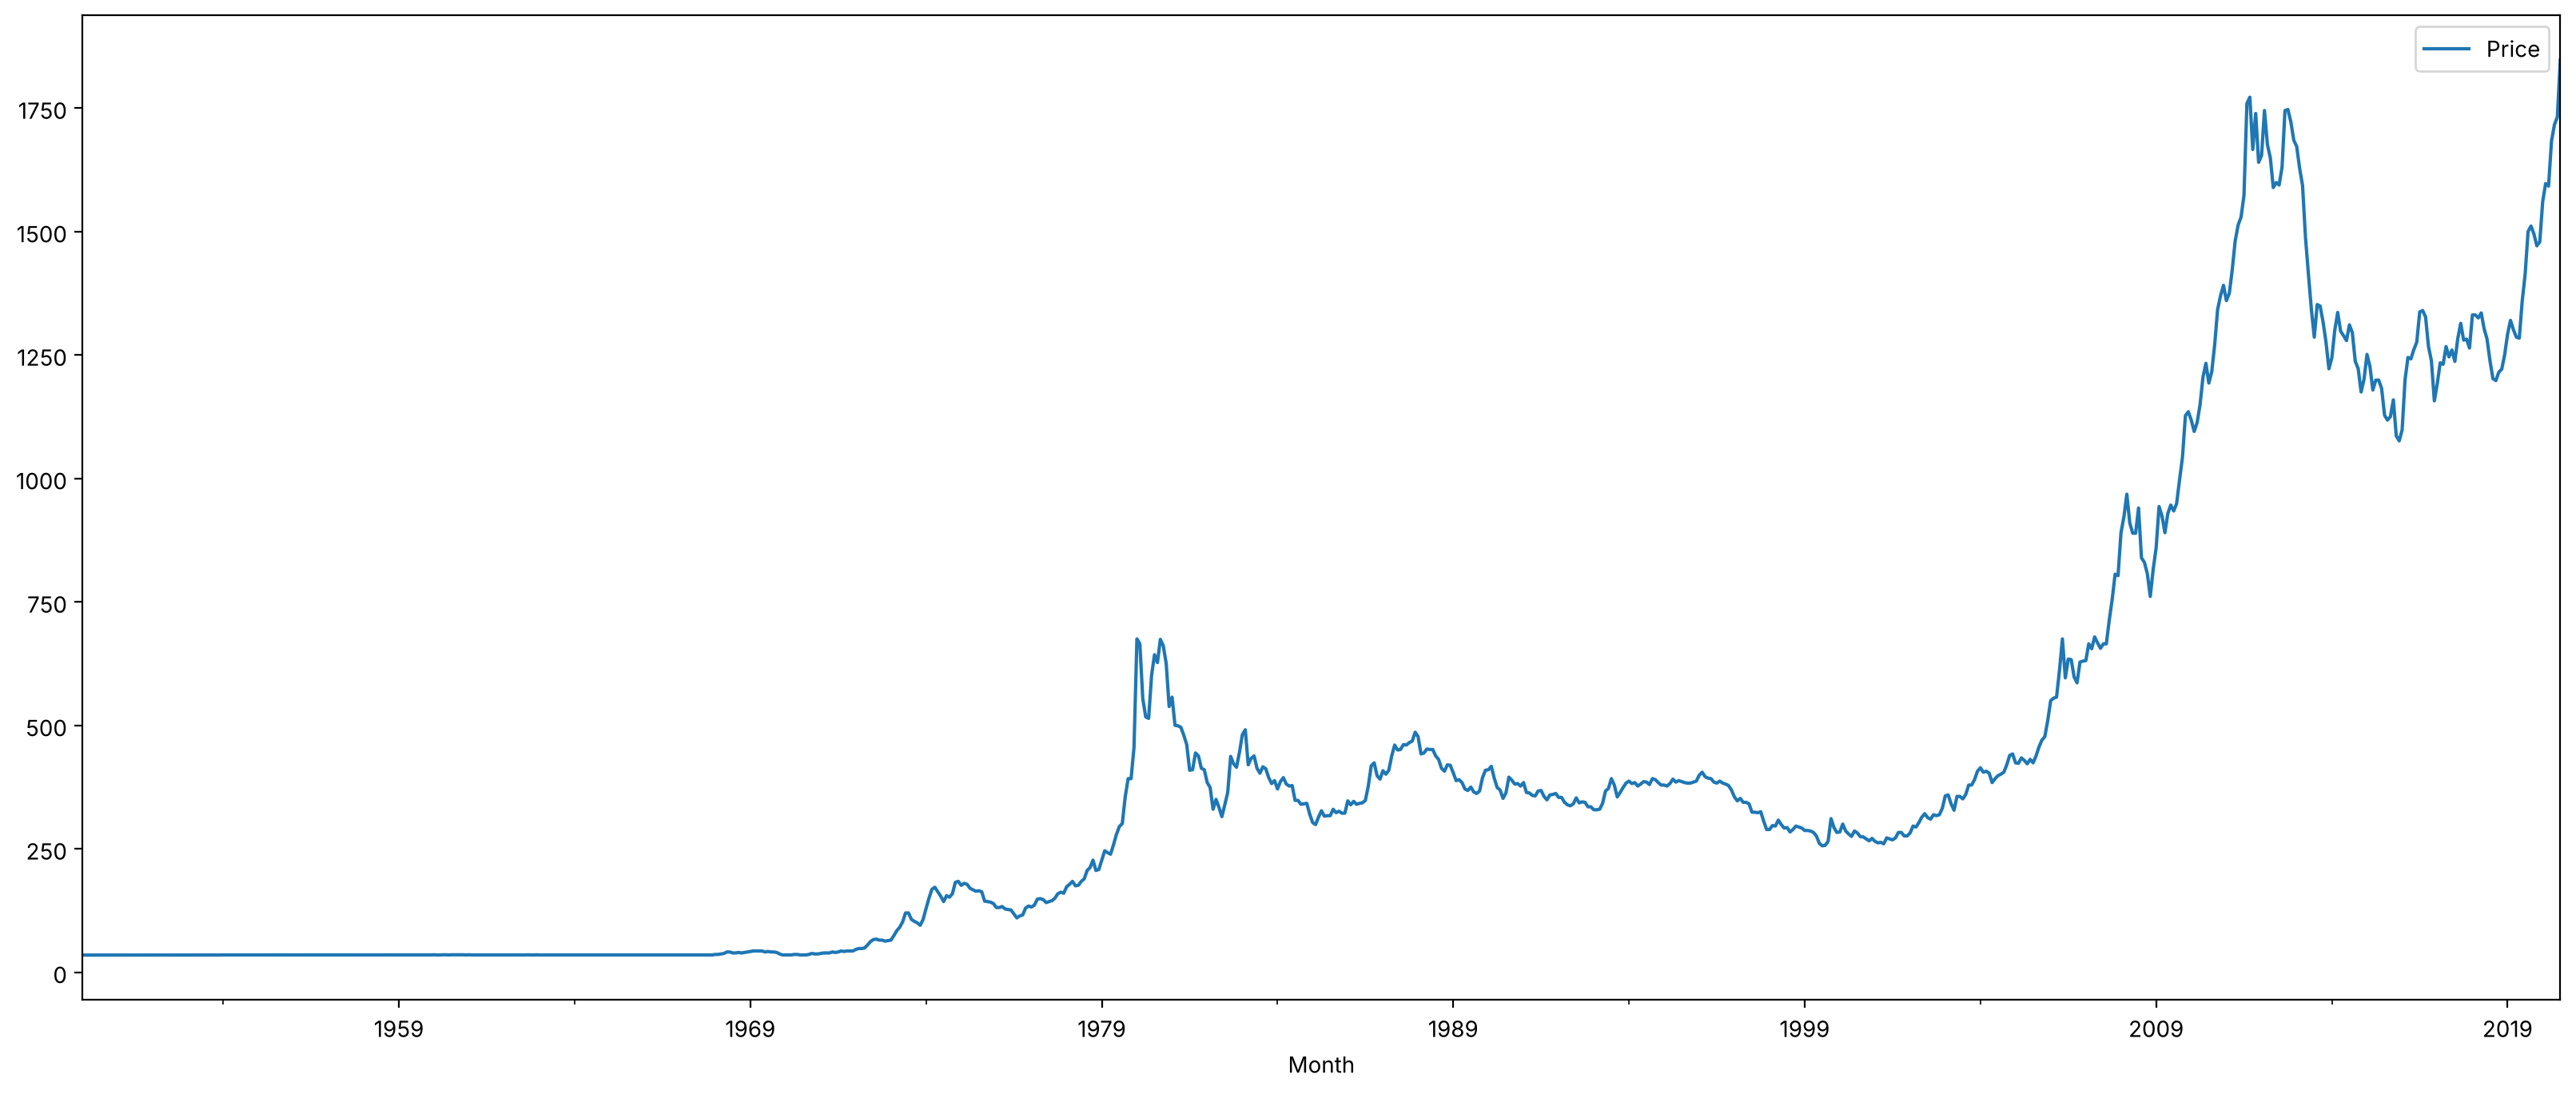

In [5]:
df.plot(kind='line',figsize=(20,8))
plt.show()

In [6]:
df.describe()

,Price
count,847.000000
mean,416.390106
std,453.647621
min,34.600000
25%,35.165000
50%,320.000000
75%,447.500000
max,1847.000000


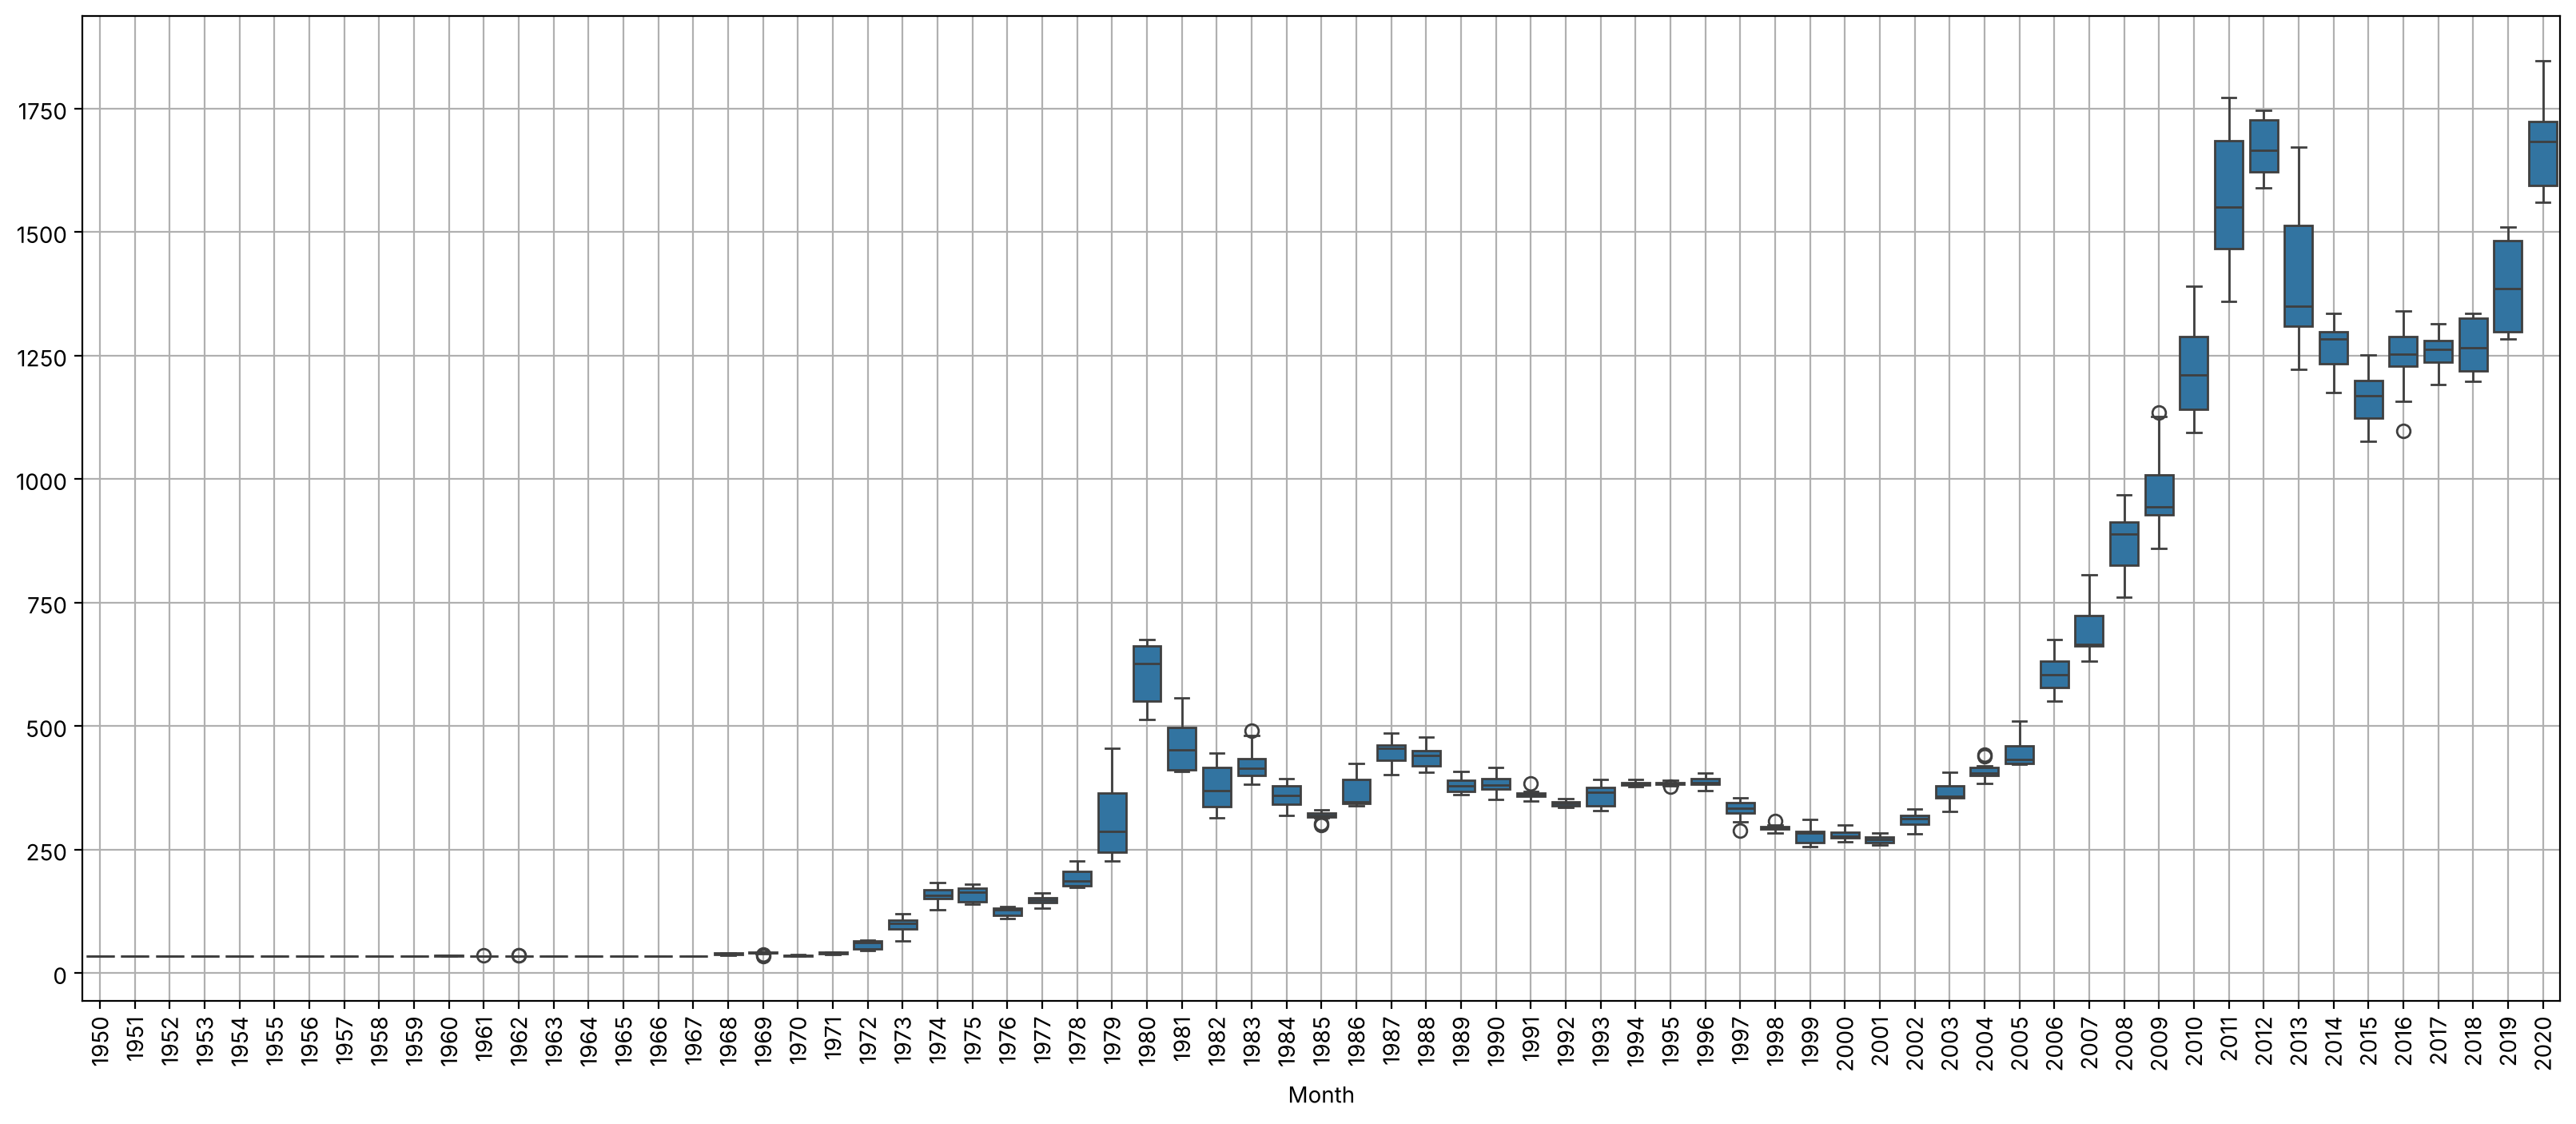

In [7]:
_,ax=plt.subplots(figsize=(20,8))
sns.boxplot(x=df.index.year,y=df.values[:,0],ax=ax)
plt.xticks(rotation=90)
plt.grid()

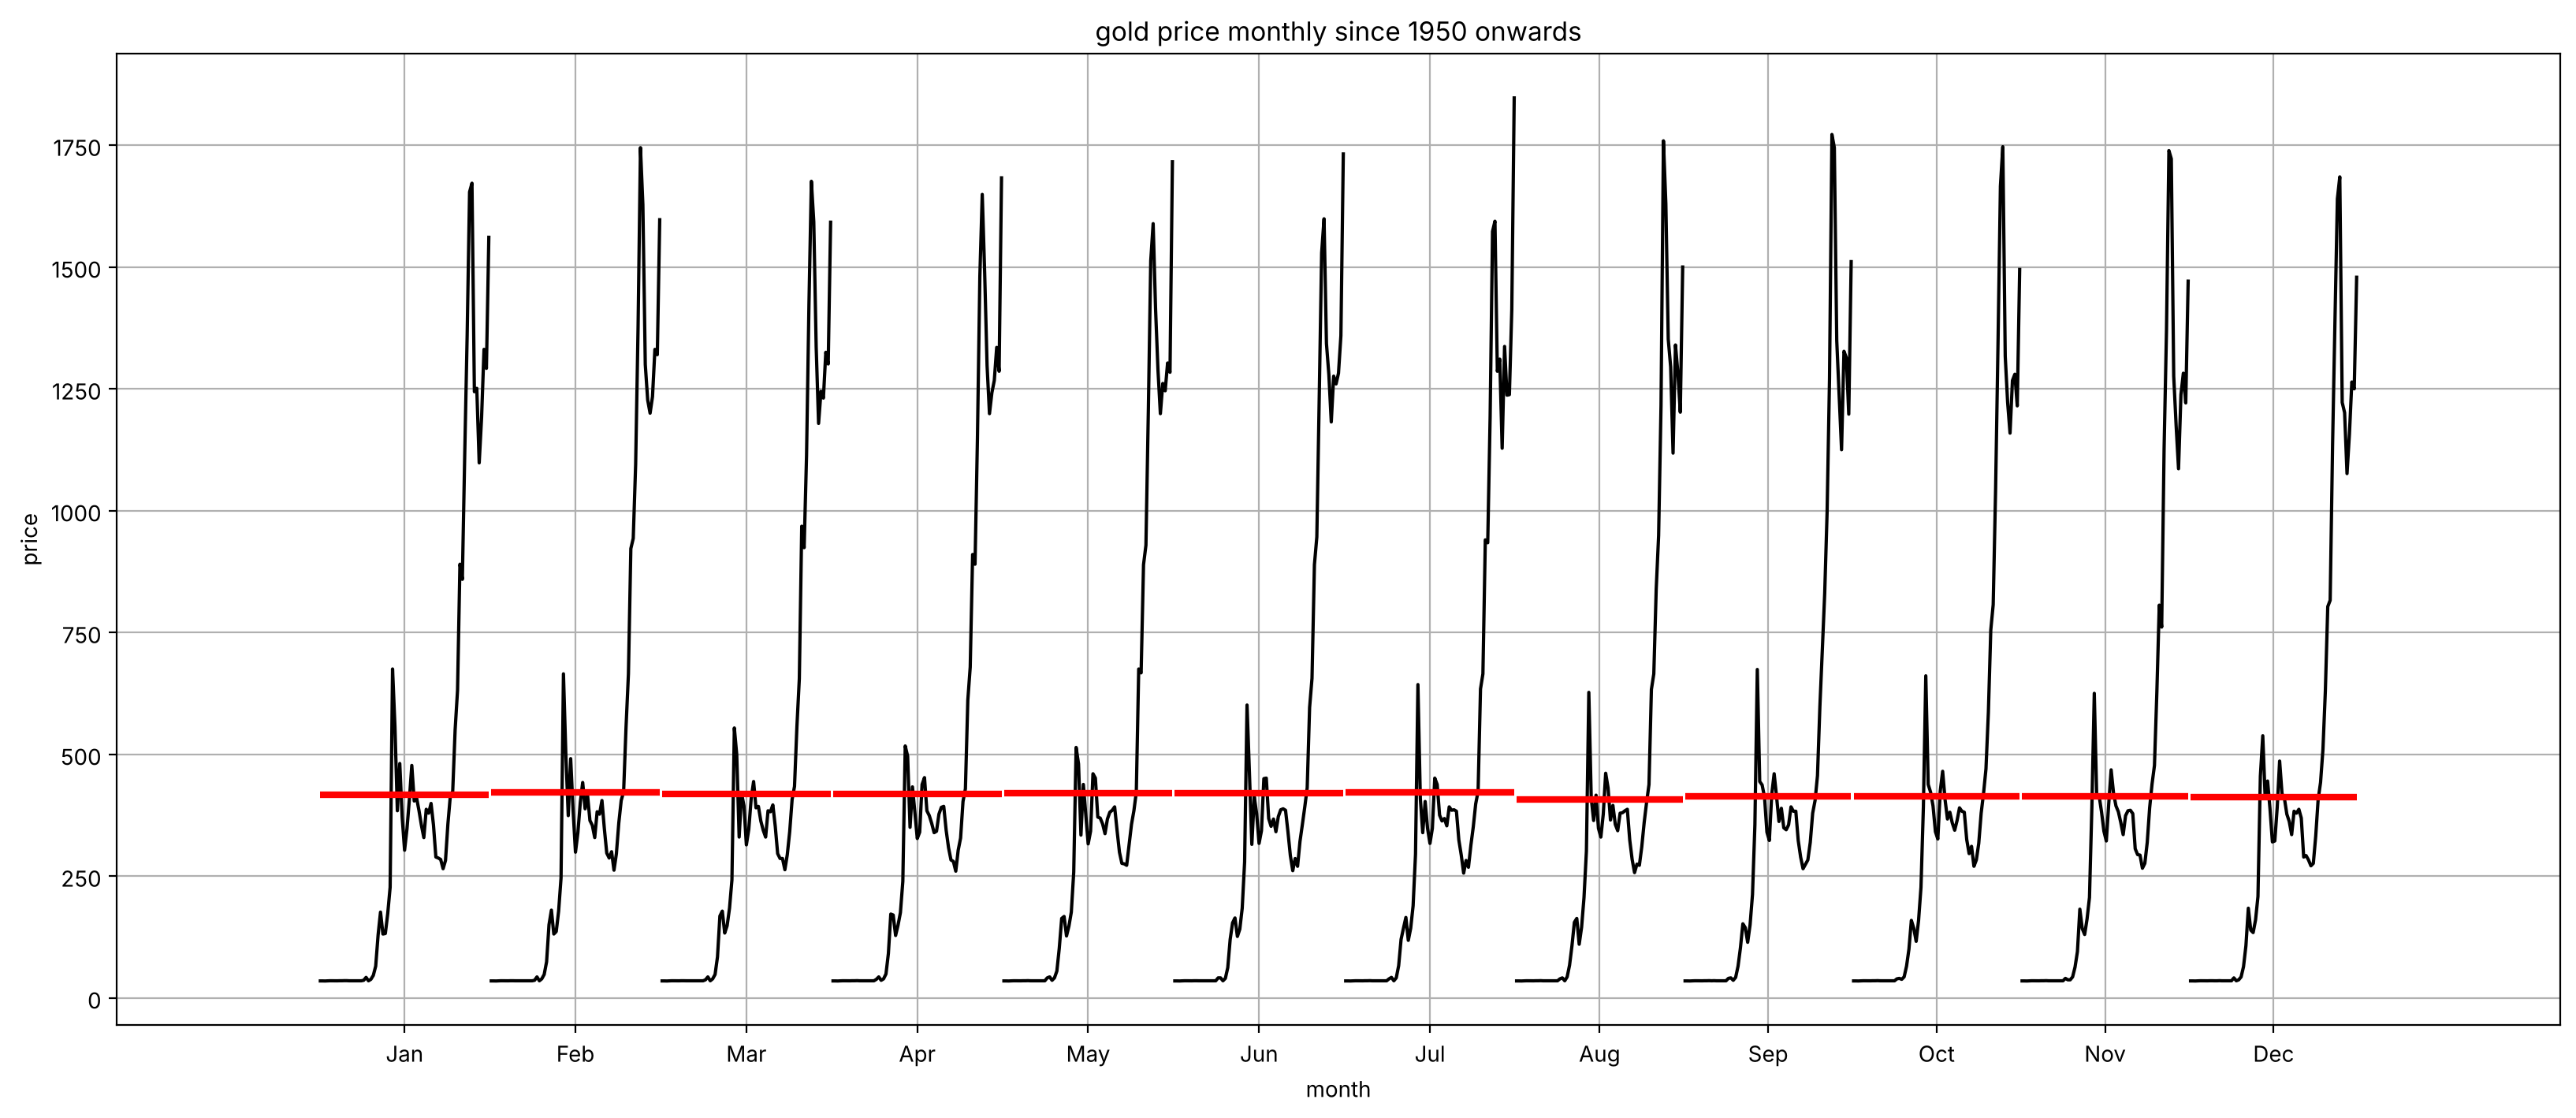

In [8]:
from statsmodels.graphics.tsaplots import month_plot

fig,ax=plt.subplots(figsize=(20,8))
month_plot(df,ylabel='gold price',ax=ax)
plt.title('gold price monthly since 1950 onwards')
plt.xlabel('month')
plt.ylabel('price')
plt.grid()

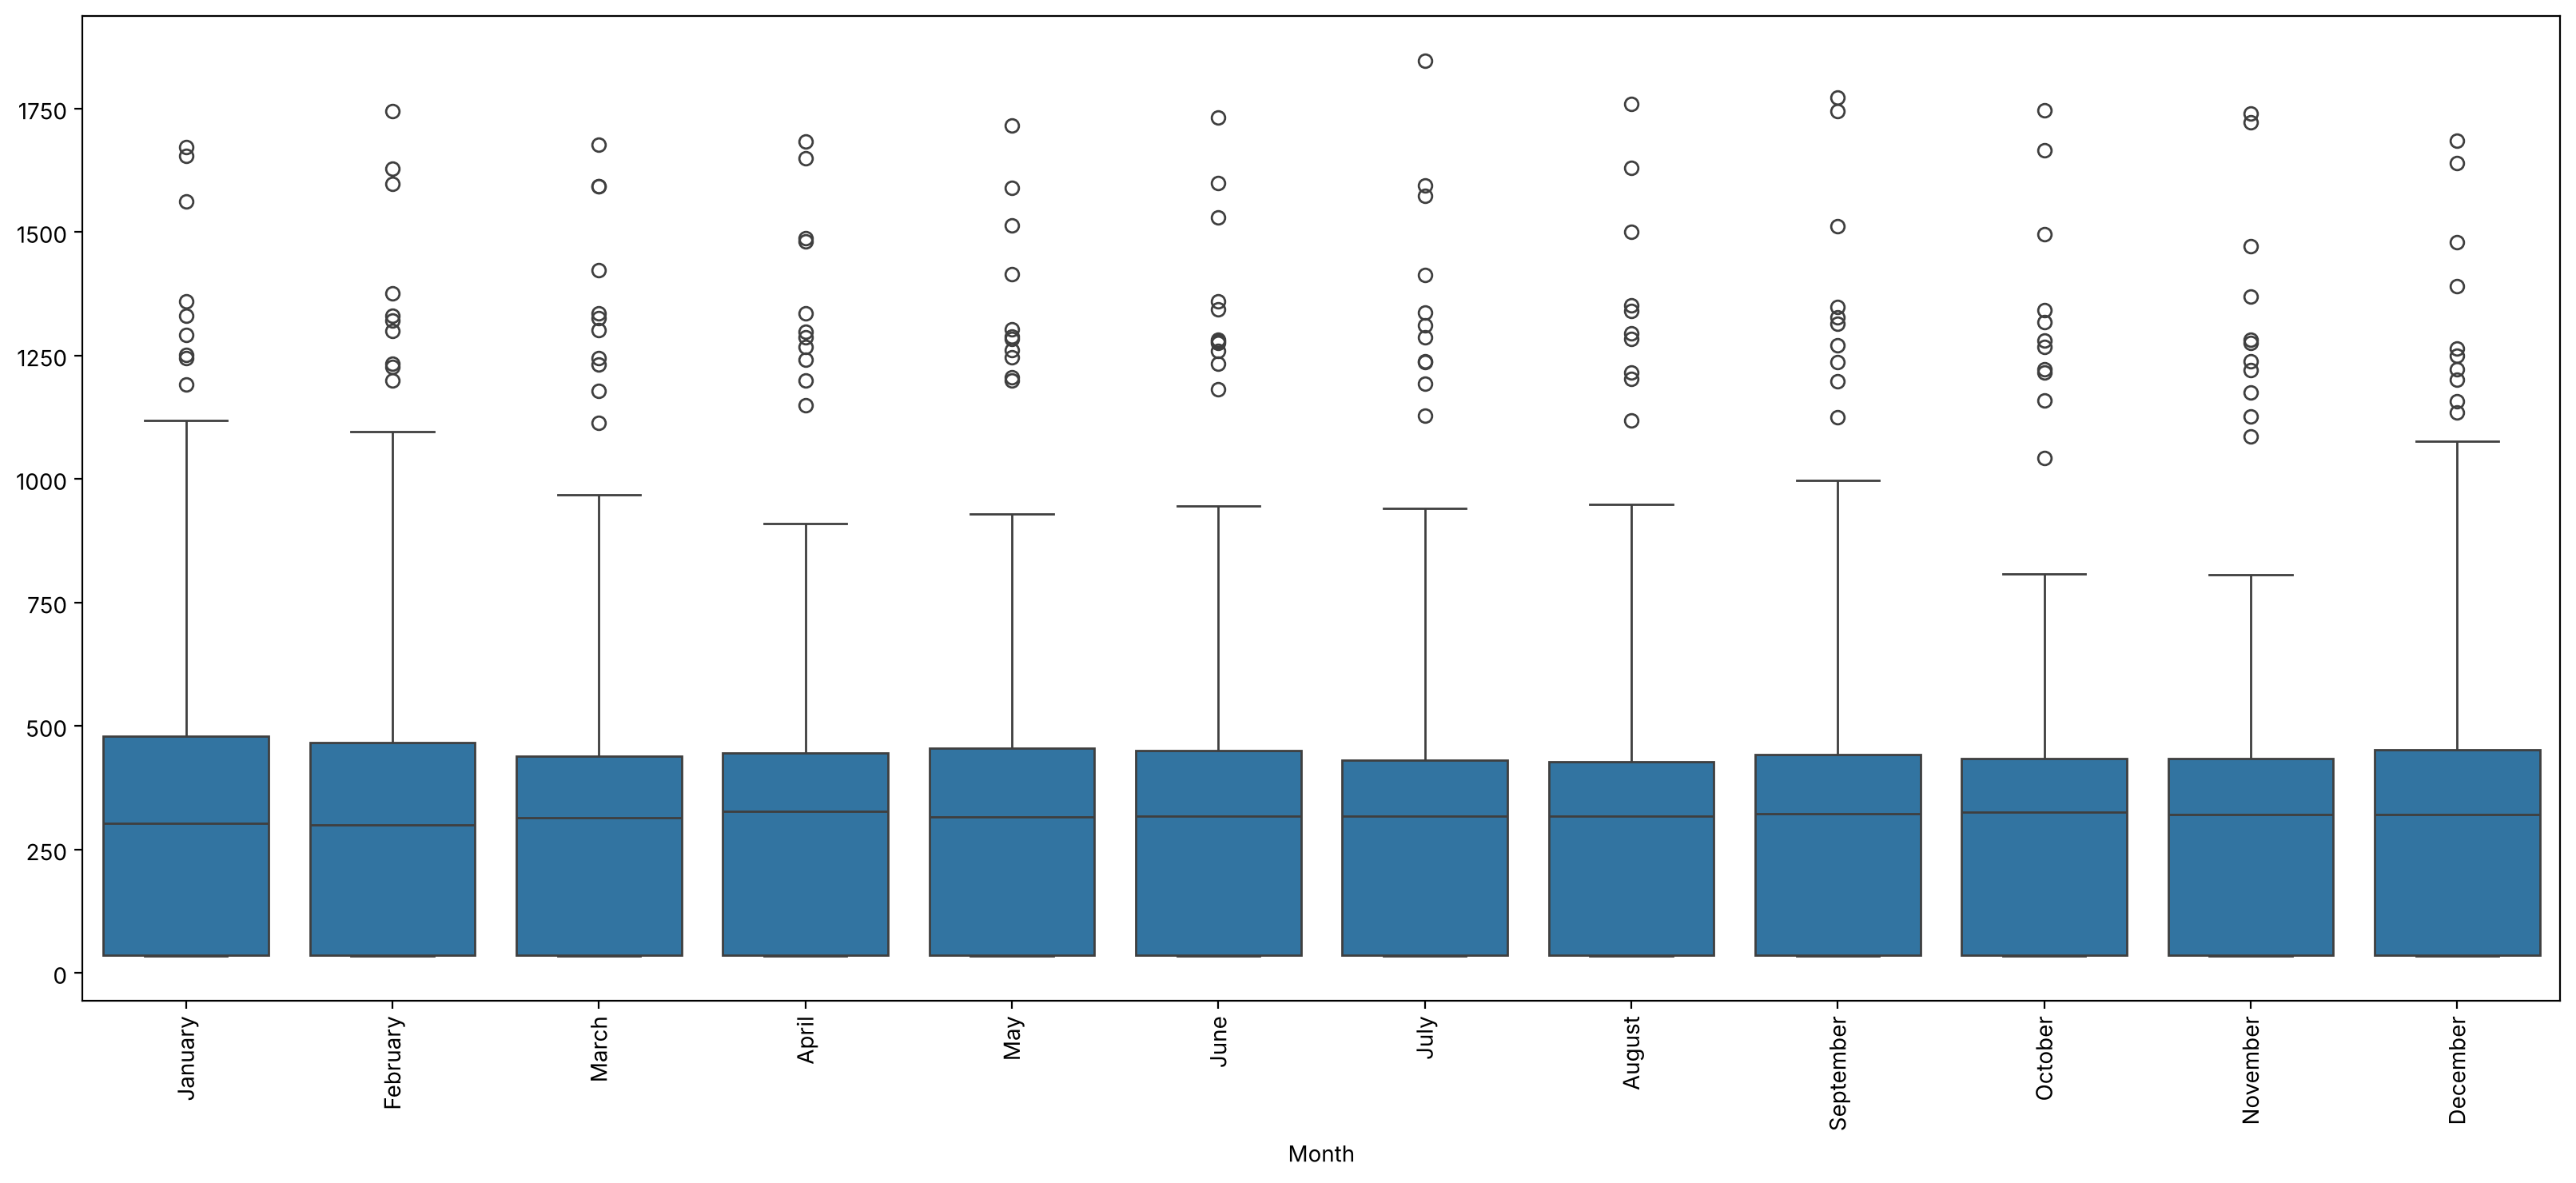

In [9]:
_,ax=plt.subplots(figsize=(20,8))
sns.boxplot(x=df.index.month_name(),y=df.values[:,0],ax=ax)
plt.xticks(rotation=90)
plt.show()

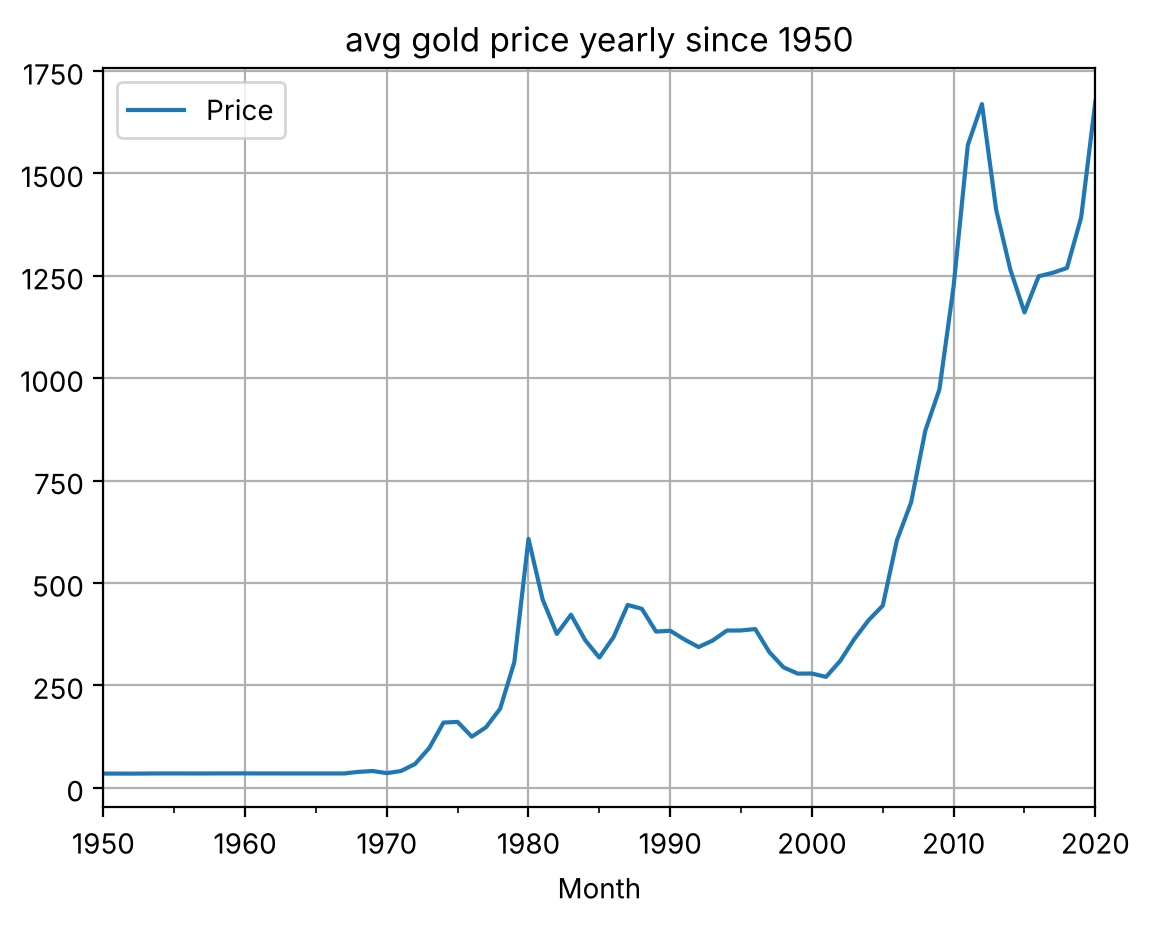

In [10]:
df_yearly_sum=df.resample('Y').mean()
df_yearly_sum.plot()
plt.title("avg gold price yearly since 1950")
plt.grid()

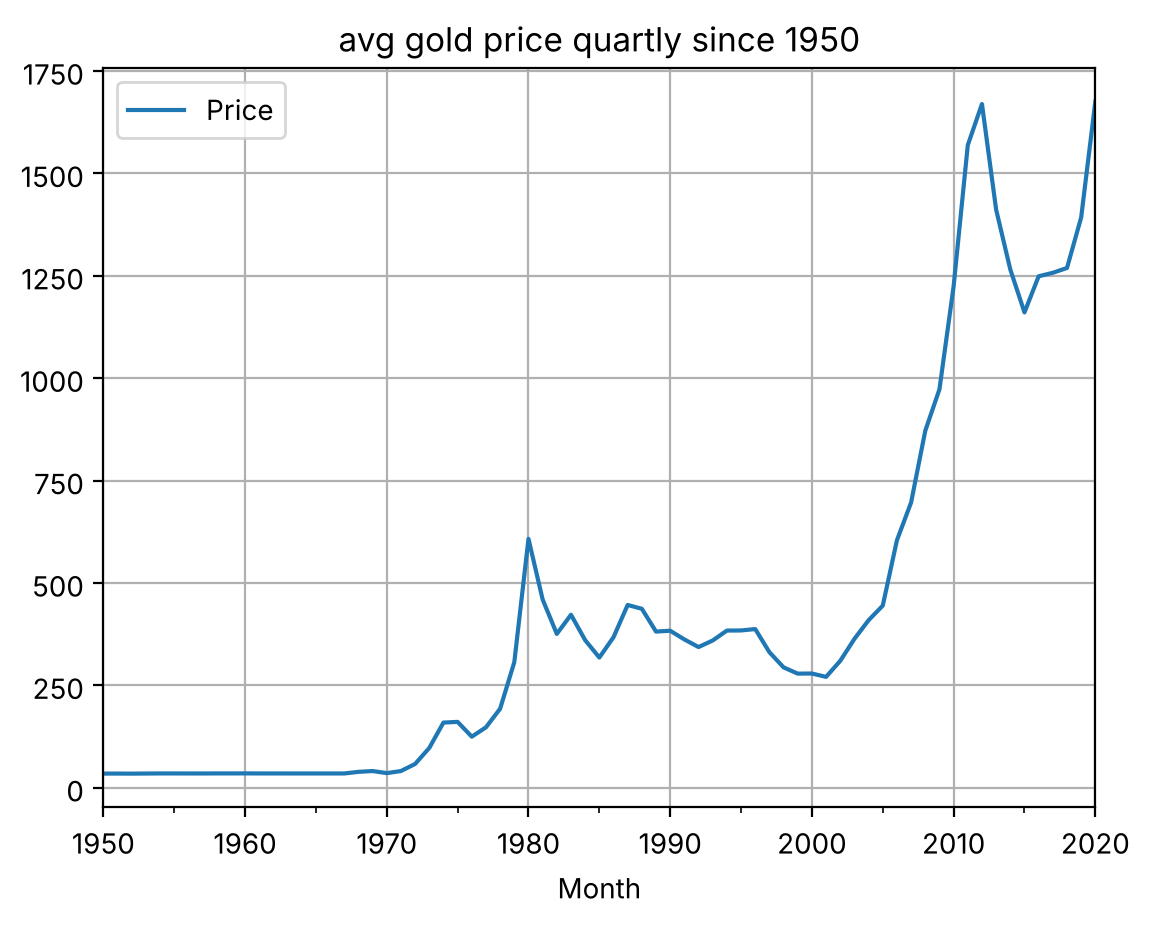

In [11]:
df_quarterly_sum=df.resample('Q').mean()
df_yearly_sum.plot()
plt.title("avg gold price quartly since 1950")
plt.grid()

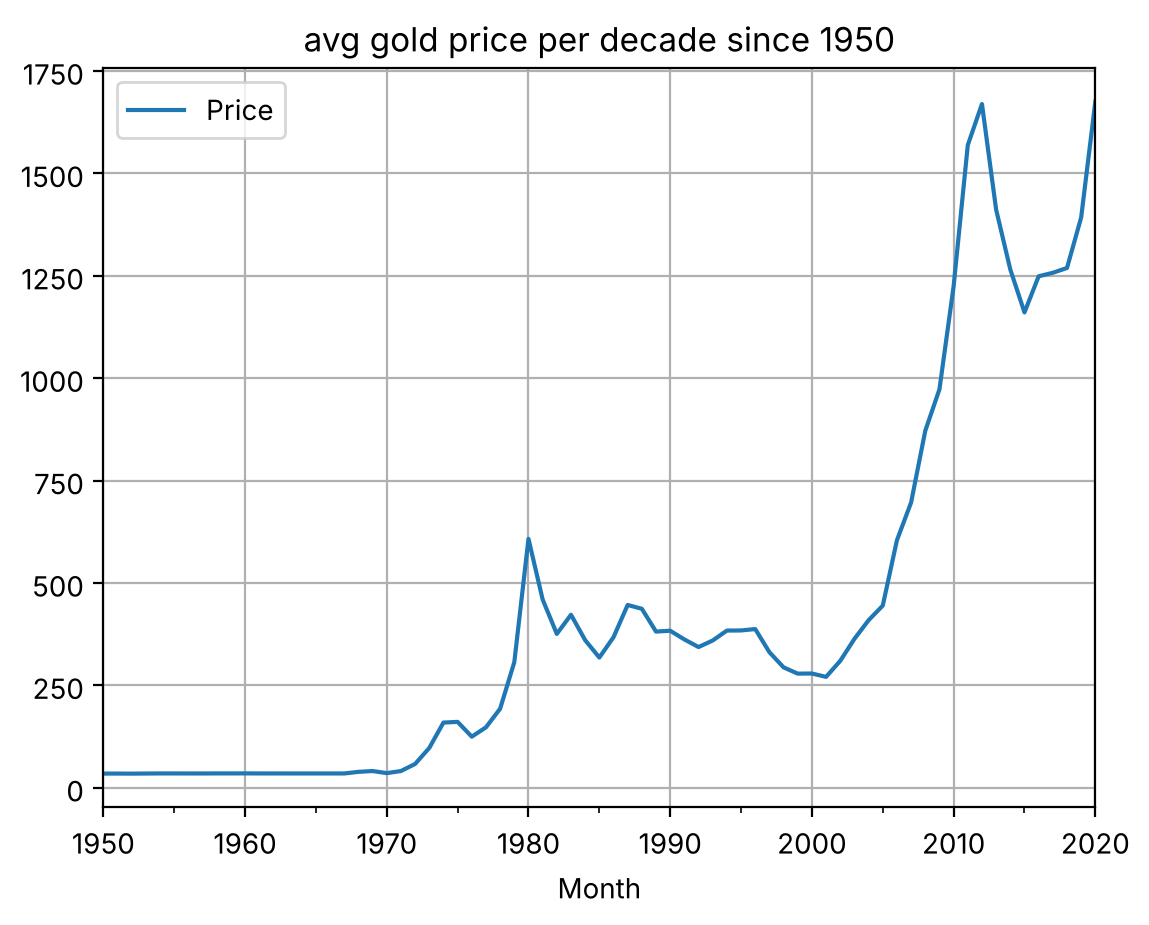

In [12]:
df_decade_sum=df.resample('10Y').mean()
df_yearly_sum.plot()
plt.title("avg gold price per decade since 1950")
plt.grid();

In [13]:
df_1=df.groupby(df.index.year).mean().rename(columns={'Price':'Mean'})
df_1=df_1.merge(df.groupby(df.index.year).std().rename(columns={'Price':'Std'}),left_index=True,right_index=True)

In [14]:
df_1['Cov_pct']=((df_1['Std']/df_1['Mean'])*100).round(2)

In [15]:
df_1

,Mean,Std,Cov_pct
Month,,,
1950,34.720000,0.000000,0.00
1951,34.720000,0.000000,0.00
1952,34.600000,0.000000,0.00
1953,34.840000,0.000000,0.00
1954,35.040000,0.000000,0.00
...,...,...,...
2016,1249.000000,72.084546,5.77
2017,1257.500000,31.887587,2.54
2018,1269.250000,54.419457,4.29


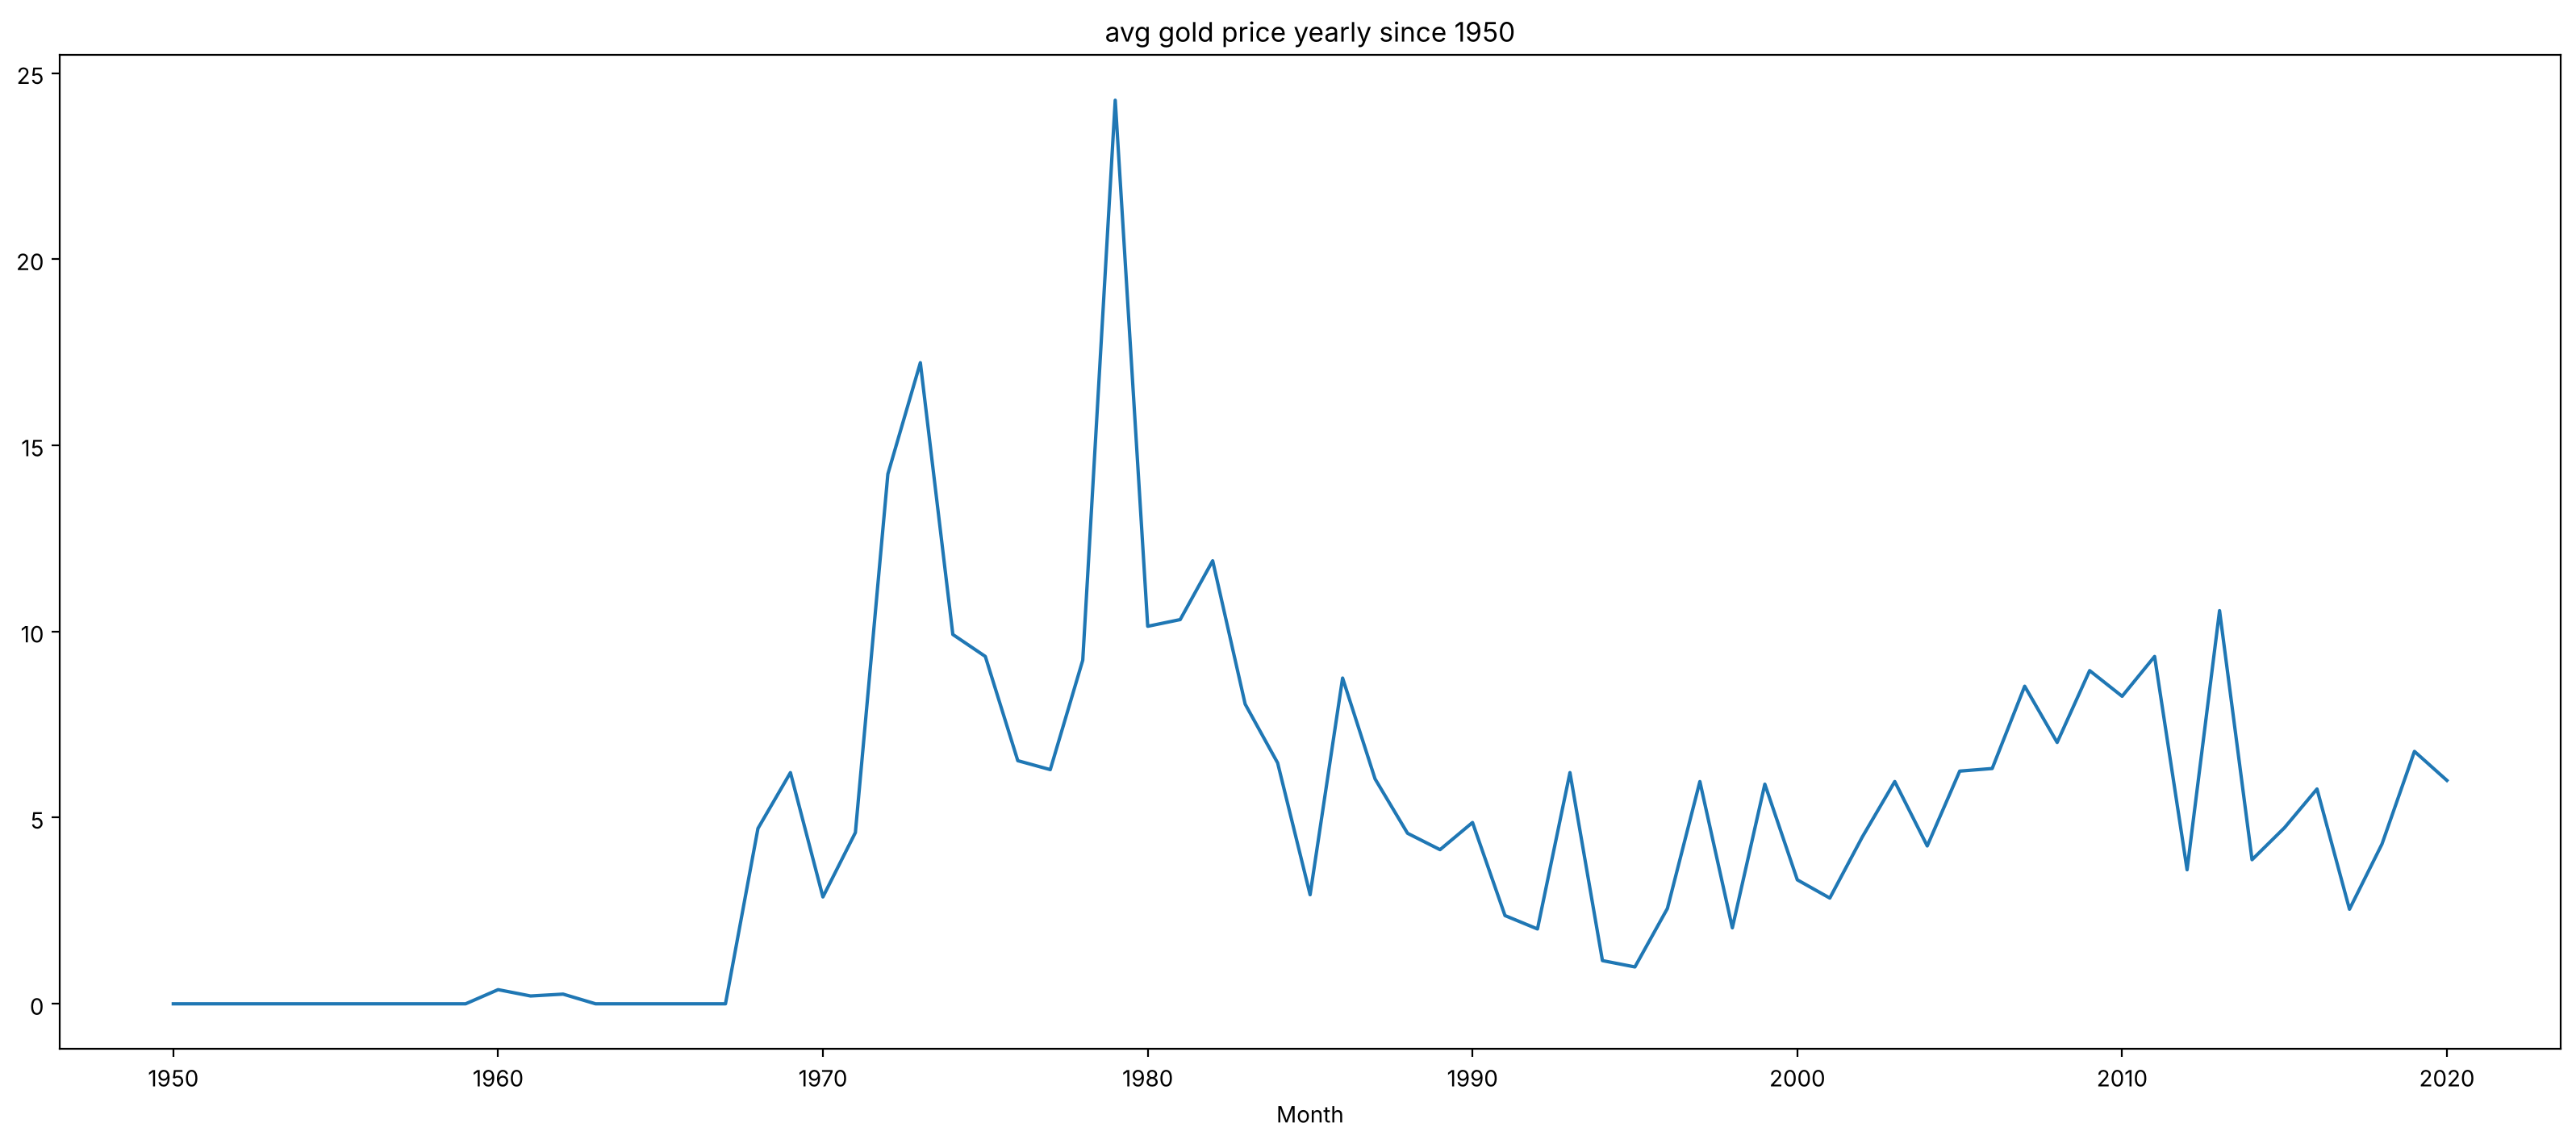

In [16]:
fig ,ax=plt.subplots(figsize=(20,8))
df_1['Cov_pct'].plot()
plt.title('avg gold price yearly since 1950')
plt.show()

### Time Forcasting 

In [17]:
train=df[df.index.year<=2015]
test=df[df.index.year>2015]

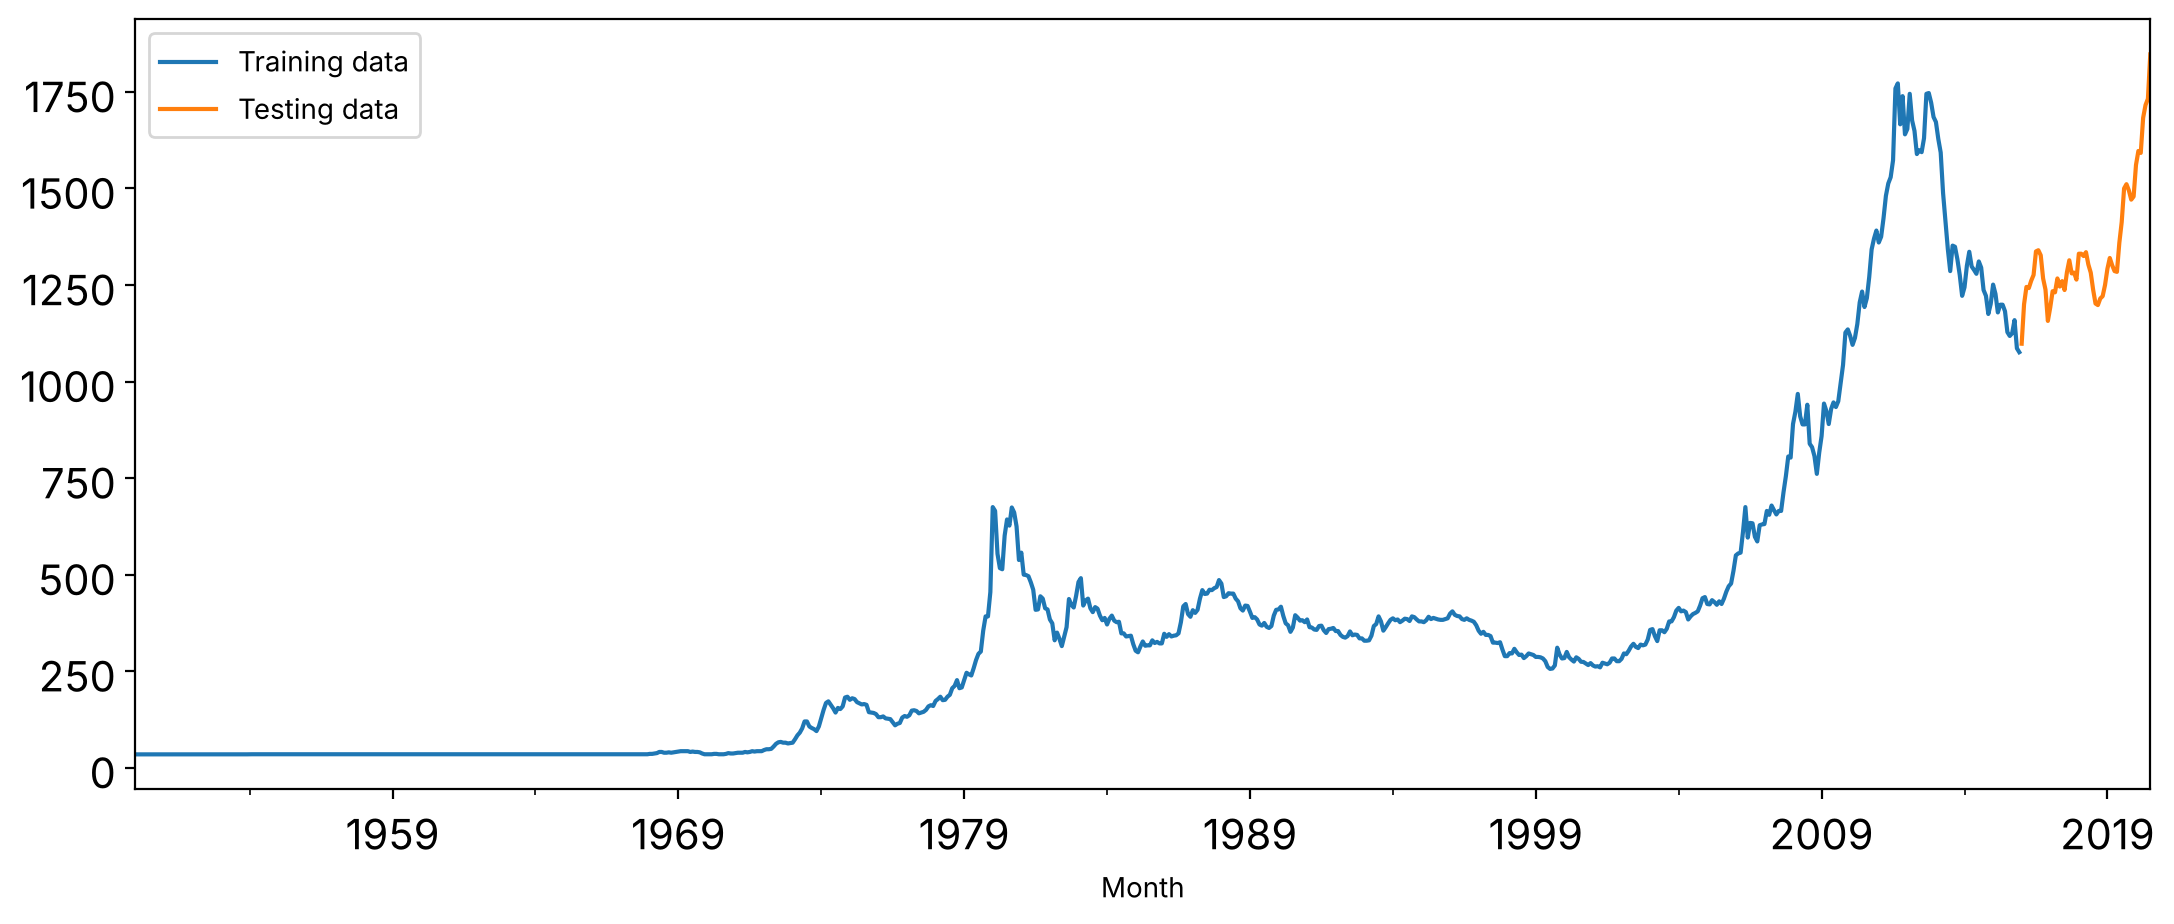

In [18]:
train['Price'].plot(figsize=(13,5),fontsize=15)
test['Price'].plot(figsize=(13,5),fontsize=15)
plt.legend(['Training data','Testing data'])
plt.show()

In [19]:
train_time = [i+1 for i in range(len(train))]
test_time = [i+len(train)+1 for i in range(len(test))]
len(train_time),len(test_time)

(792, 55)

In [20]:
LR_train=train.copy()
LR_test=test.copy()

In [21]:
LR_train['time']=train_time
LR_test['time']=test_time

In [22]:
lr=LinearRegression()
lr.fit(LR_train[['time']],LR_train['Price'].values)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.37]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-190.9
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


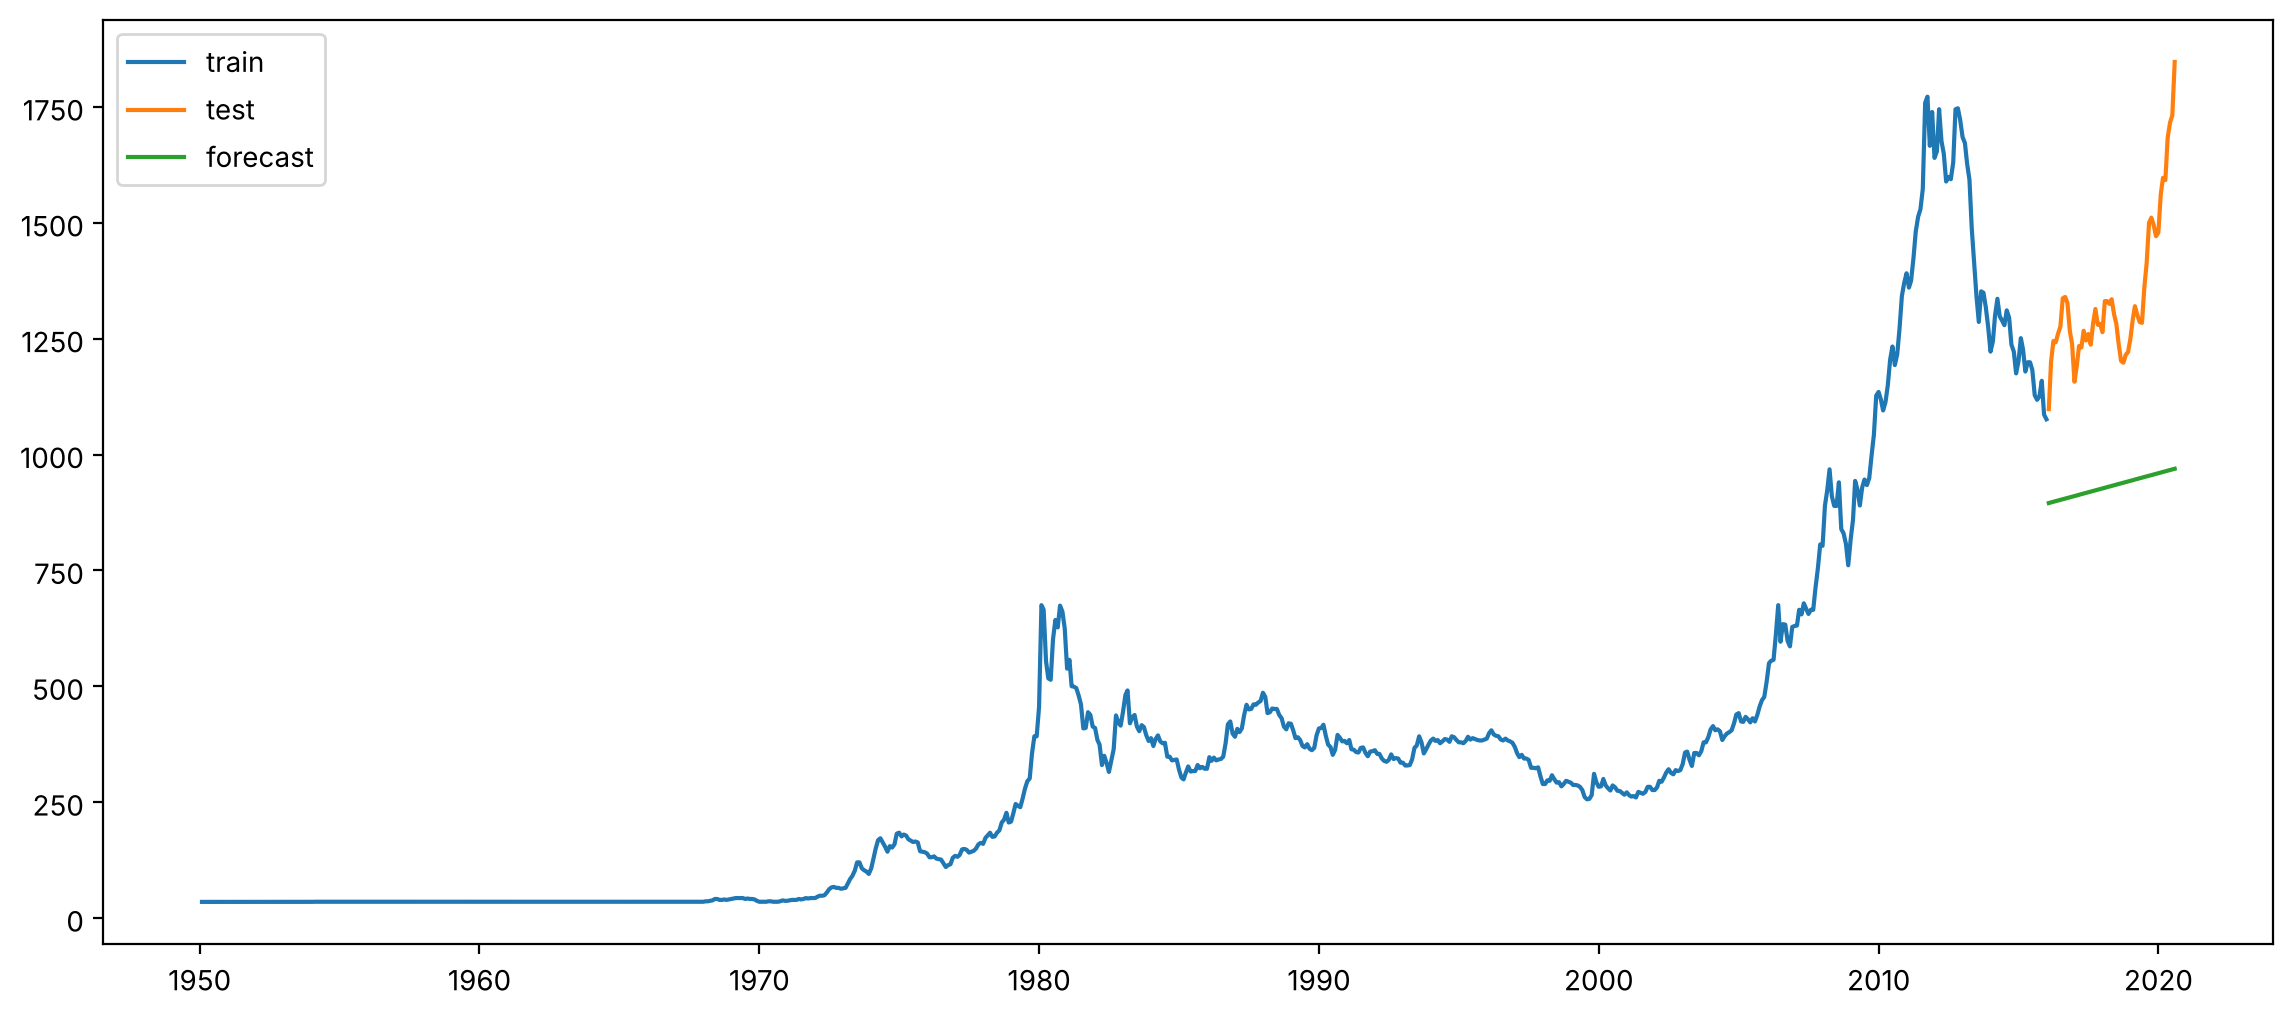

In [23]:
test_predictions_model1=lr.predict(LR_test[['time']])
LR_test['forecast']=test_predictions_model1

plt.figure(figsize=(14,6))
plt.plot(train['Price'],label='train')
plt.plot(test['Price'],label='test')
plt.plot(LR_test['forecast'],label='forecast')
plt.legend(loc='best')
plt.show()

In [24]:
def map(actual,pred):
    return round((np.mean(abs(actual-pred)/actual))*100,2)

In [25]:
mape_model1_test=map(test['Price'].values,test_predictions_model1)

In [26]:
mape_model1_test

np.float64(29.78)

---
## ARIMA & SARIMA models

The linear-regression baseline above reaches a MAPE of ~29.8 %. We now model the *autocorrelation* structure of the series with **ARIMA** and its seasonal extension **SARIMA**, then compare every model on the same hold-out period (2016 → 2020).

**Workflow:** stationarity tests → ACF/PACF → grid search (AIC) → residual diagnostics → accuracy comparison → future forecast.

In [27]:
import os, itertools, time
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.stats.diagnostic import acorr_ljungbox

os.makedirs('images', exist_ok=True)
sns.set_style('whitegrid')

def save(name):
    plt.savefig(f'images/{name}.png', dpi=140, bbox_inches='tight')

# --- accuracy metrics (named so they do not shadow Python built-ins) ---
def mape_pct(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return round(np.mean(np.abs(actual - pred) / actual) * 100, 2)

def rmse(actual, pred):
    return round(float(np.sqrt(np.mean((np.asarray(actual, float) - np.asarray(pred, float)) ** 2))), 2)

def mae(actual, pred):
    return round(float(np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float)))), 2)

### 1. Stationarity tests
ARIMA needs a stationary series. **ADF**: H0 = unit root (non-stationary). **KPSS**: H0 = stationary. We want ADF p < 0.05 *and* KPSS p > 0.05.

In [28]:
def stationarity_report(series, name):
    adf_p = adfuller(series.dropna())[1]
    kpss_p = kpss(series.dropna(), regression='c', nlags='auto')[1]
    verdict = 'stationary' if (adf_p < 0.05 and kpss_p > 0.05) else 'NOT stationary'
    return {'series': name, 'ADF p-value': round(adf_p, 4), 'KPSS p-value': round(kpss_p, 4), 'verdict': verdict}

y_train = train['Price']
y_test  = test['Price']

pd.DataFrame([
    stationarity_report(y_train, 'Price (level)'),
    stationarity_report(y_train.diff(), 'Price (1st difference)'),
    stationarity_report(np.log(y_train).diff(), 'log(Price) (1st difference)'),
])

,series,ADF p-value,KPSS p-value,verdict
0,Price (level),0.7874,0.01,NOT stationary
1,Price (1st difference),0.0000,0.10,stationary
2,log(Price) (1st difference),0.0000,0.10,stationary


A first difference (**d = 1**) is needed. Next, ACF/PACF of the differenced series suggest the AR/MA orders, and the decomposition shows whether a seasonal component exists.

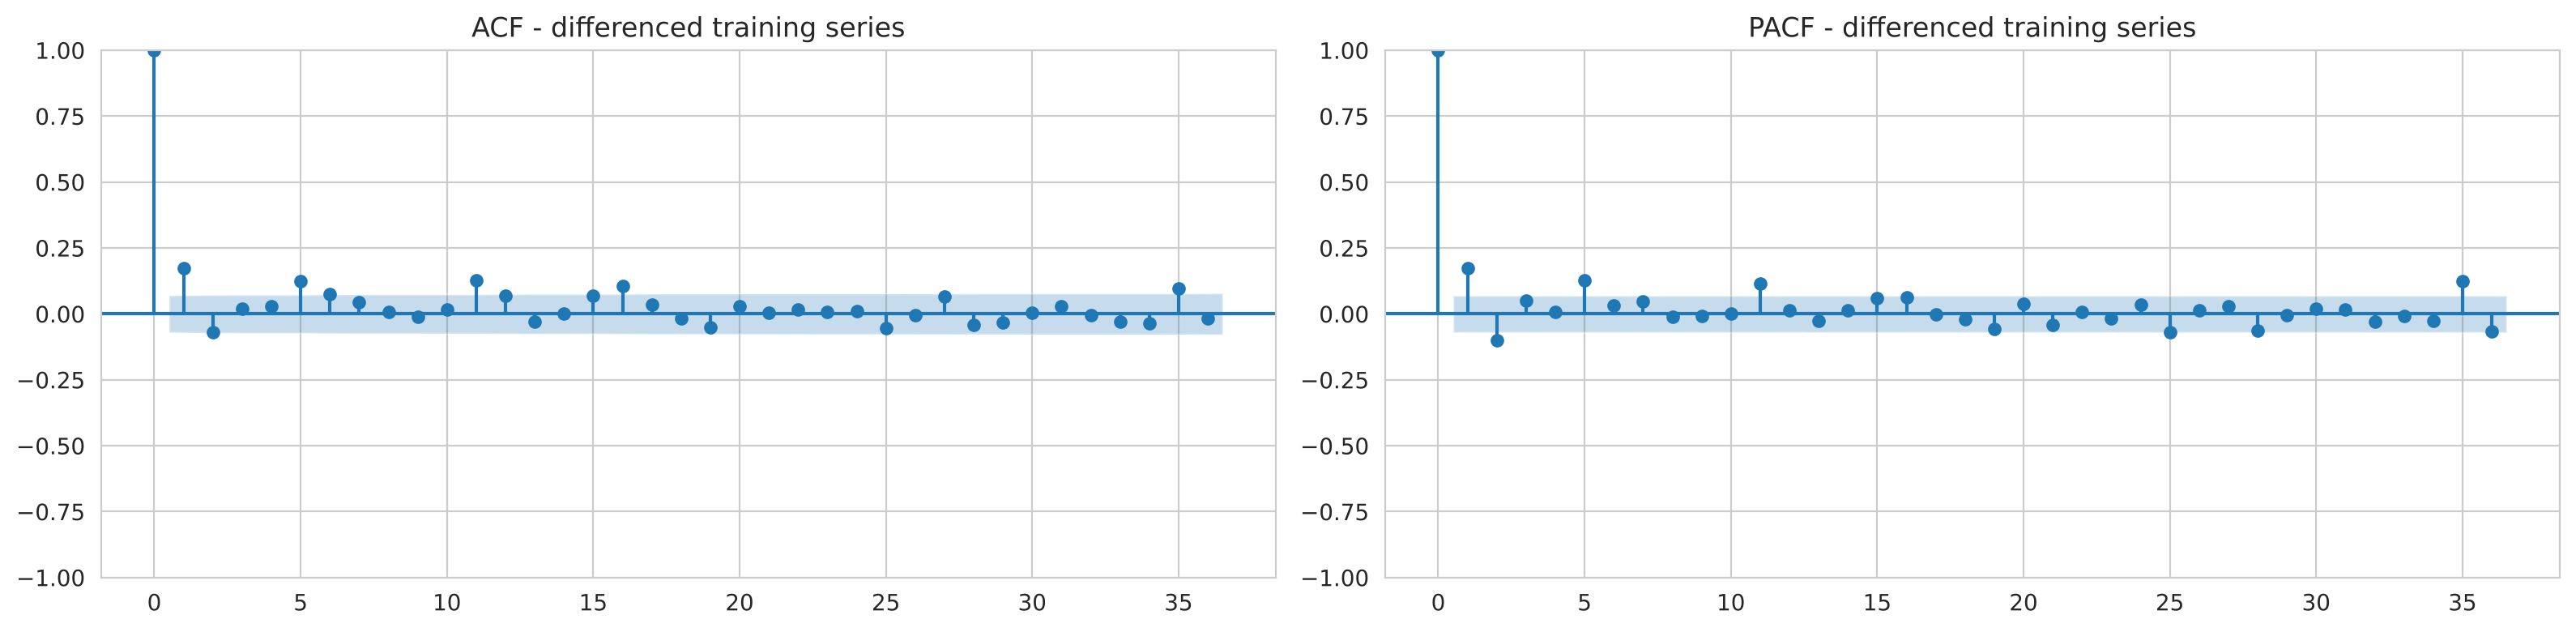

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(y_train.diff().dropna(), lags=36, ax=axes[0]);  axes[0].set_title('ACF - differenced training series')
plot_pacf(y_train.diff().dropna(), lags=36, ax=axes[1], method='ywm'); axes[1].set_title('PACF - differenced training series')
plt.tight_layout(); save('acf_pacf'); plt.show()

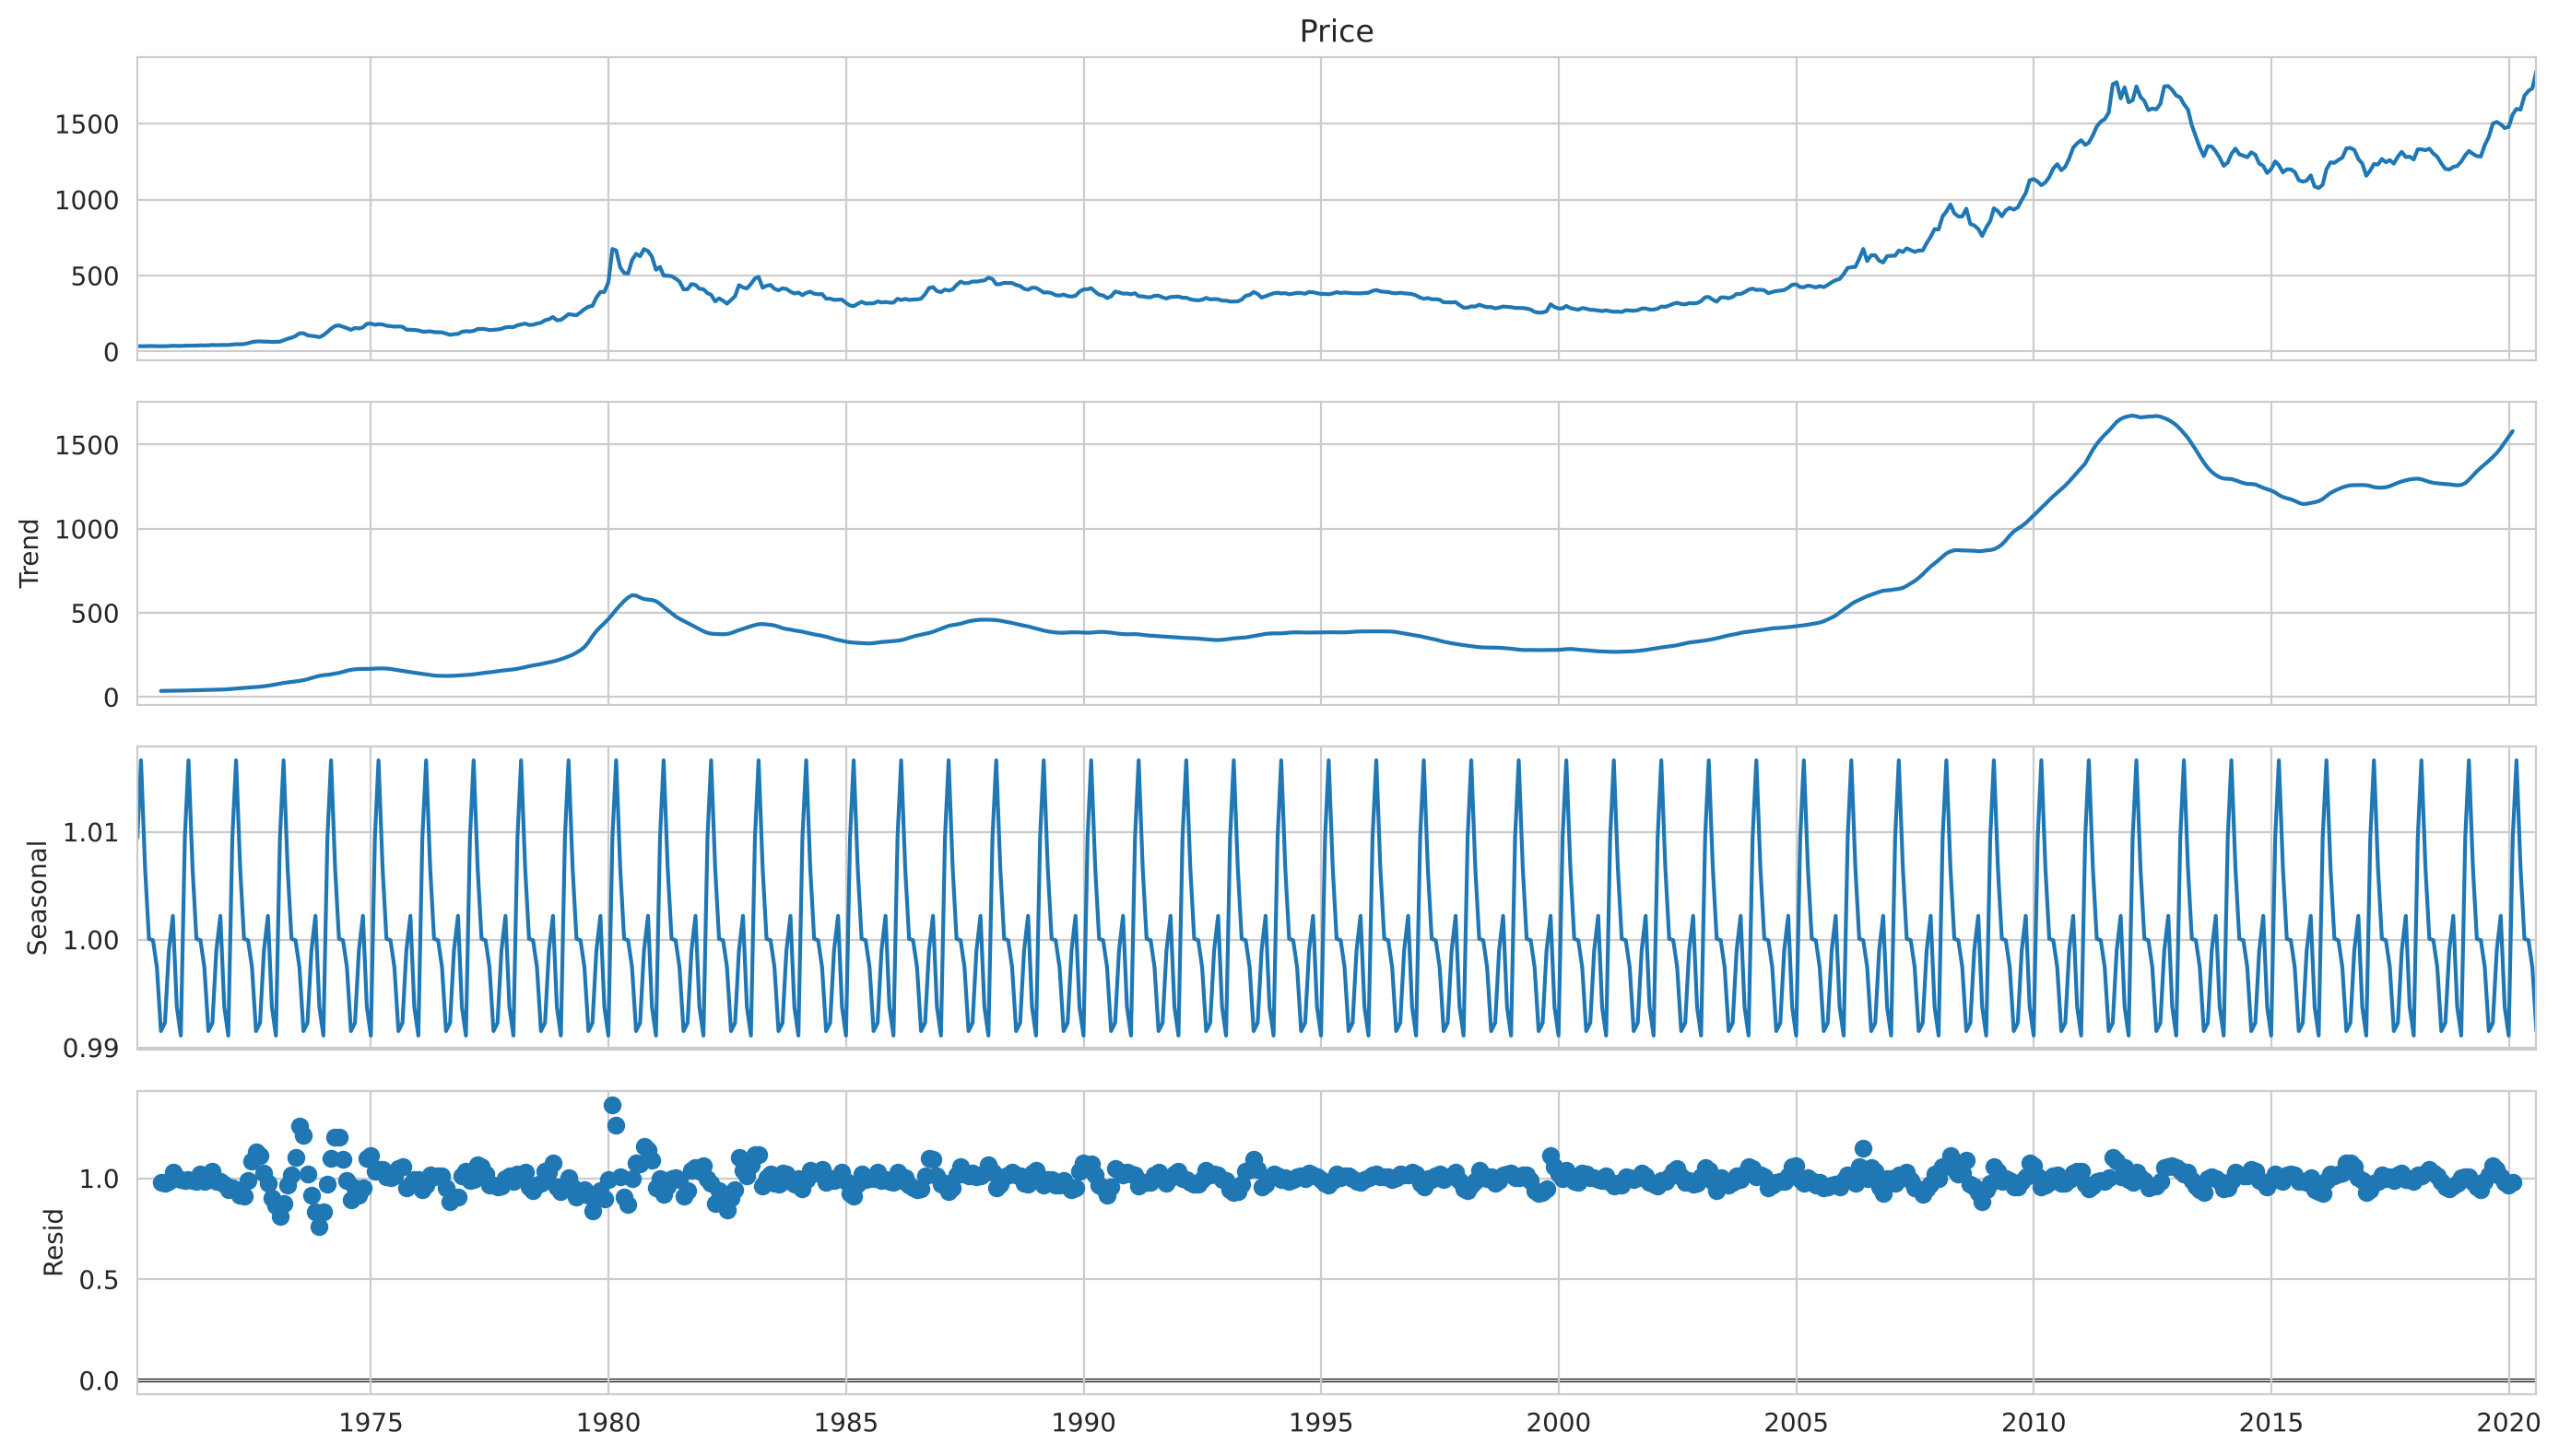

In [30]:
# Decomposition on the post-1970 free-market era (before that gold was price-fixed)
dec = seasonal_decompose(df.loc['1970':, 'Price'], model='multiplicative', period=12)
fig = dec.plot(); fig.set_size_inches(14, 8)
plt.tight_layout(); save('decomposition'); plt.show()

### 2. ARIMA(p, 1, q) - grid search on AIC

In [31]:
t0 = time.time()
arima_results = []
for p, q in itertools.product(range(4), range(4)):
    try:
        fit = ARIMA(y_train, order=(p, 1, q)).fit()
        arima_results.append({'order': (p, 1, q), 'AIC': fit.aic, 'BIC': fit.bic})
    except Exception:
        continue

arima_grid = pd.DataFrame(arima_results).sort_values('AIC').reset_index(drop=True)
print(f'{len(arima_grid)} models fitted in {time.time()-t0:.1f}s')
arima_grid.head(5)

16 models fitted in 2.6s


,order,AIC,BIC
0,"(1, 1, 3)",7205.323626,7228.690116
1,"(2, 1, 2)",7206.567816,7229.934306
2,"(2, 1, 3)",7206.865468,7234.905256
3,"(3, 1, 3)",7207.124202,7239.837288
4,"(3, 1, 2)",7208.478696,7236.518484


In [32]:
best_arima_order = arima_grid.loc[0, 'order']
arima_fit = ARIMA(y_train, order=best_arima_order).fit()
print(arima_fit.summary())

arima_fc = arima_fit.get_forecast(steps=len(y_test))
arima_pred = arima_fc.predicted_mean
arima_ci = arima_fc.conf_int(alpha=0.05)
arima_pred.index = y_test.index; arima_ci.index = y_test.index

                               SARIMAX Results                                
Dep. Variable:                  Price   No. Observations:                  792
Model:                 ARIMA(1, 1, 3)   Log Likelihood               -3597.662
Date:                Wed, 25 Nov 2026   AIC                           7205.324
Time:                        10:47:21   BIC                           7228.690
Sample:                    01-31-1950   HQIC                          7214.305
                         - 12-31-2015                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9325      0.024     38.129      0.000       0.885       0.980
ma.L1         -0.7482      0.032    -23.500      0.000      -0.811      -0.686
ma.L2         -0.2713      0.020    -13.609      0.0

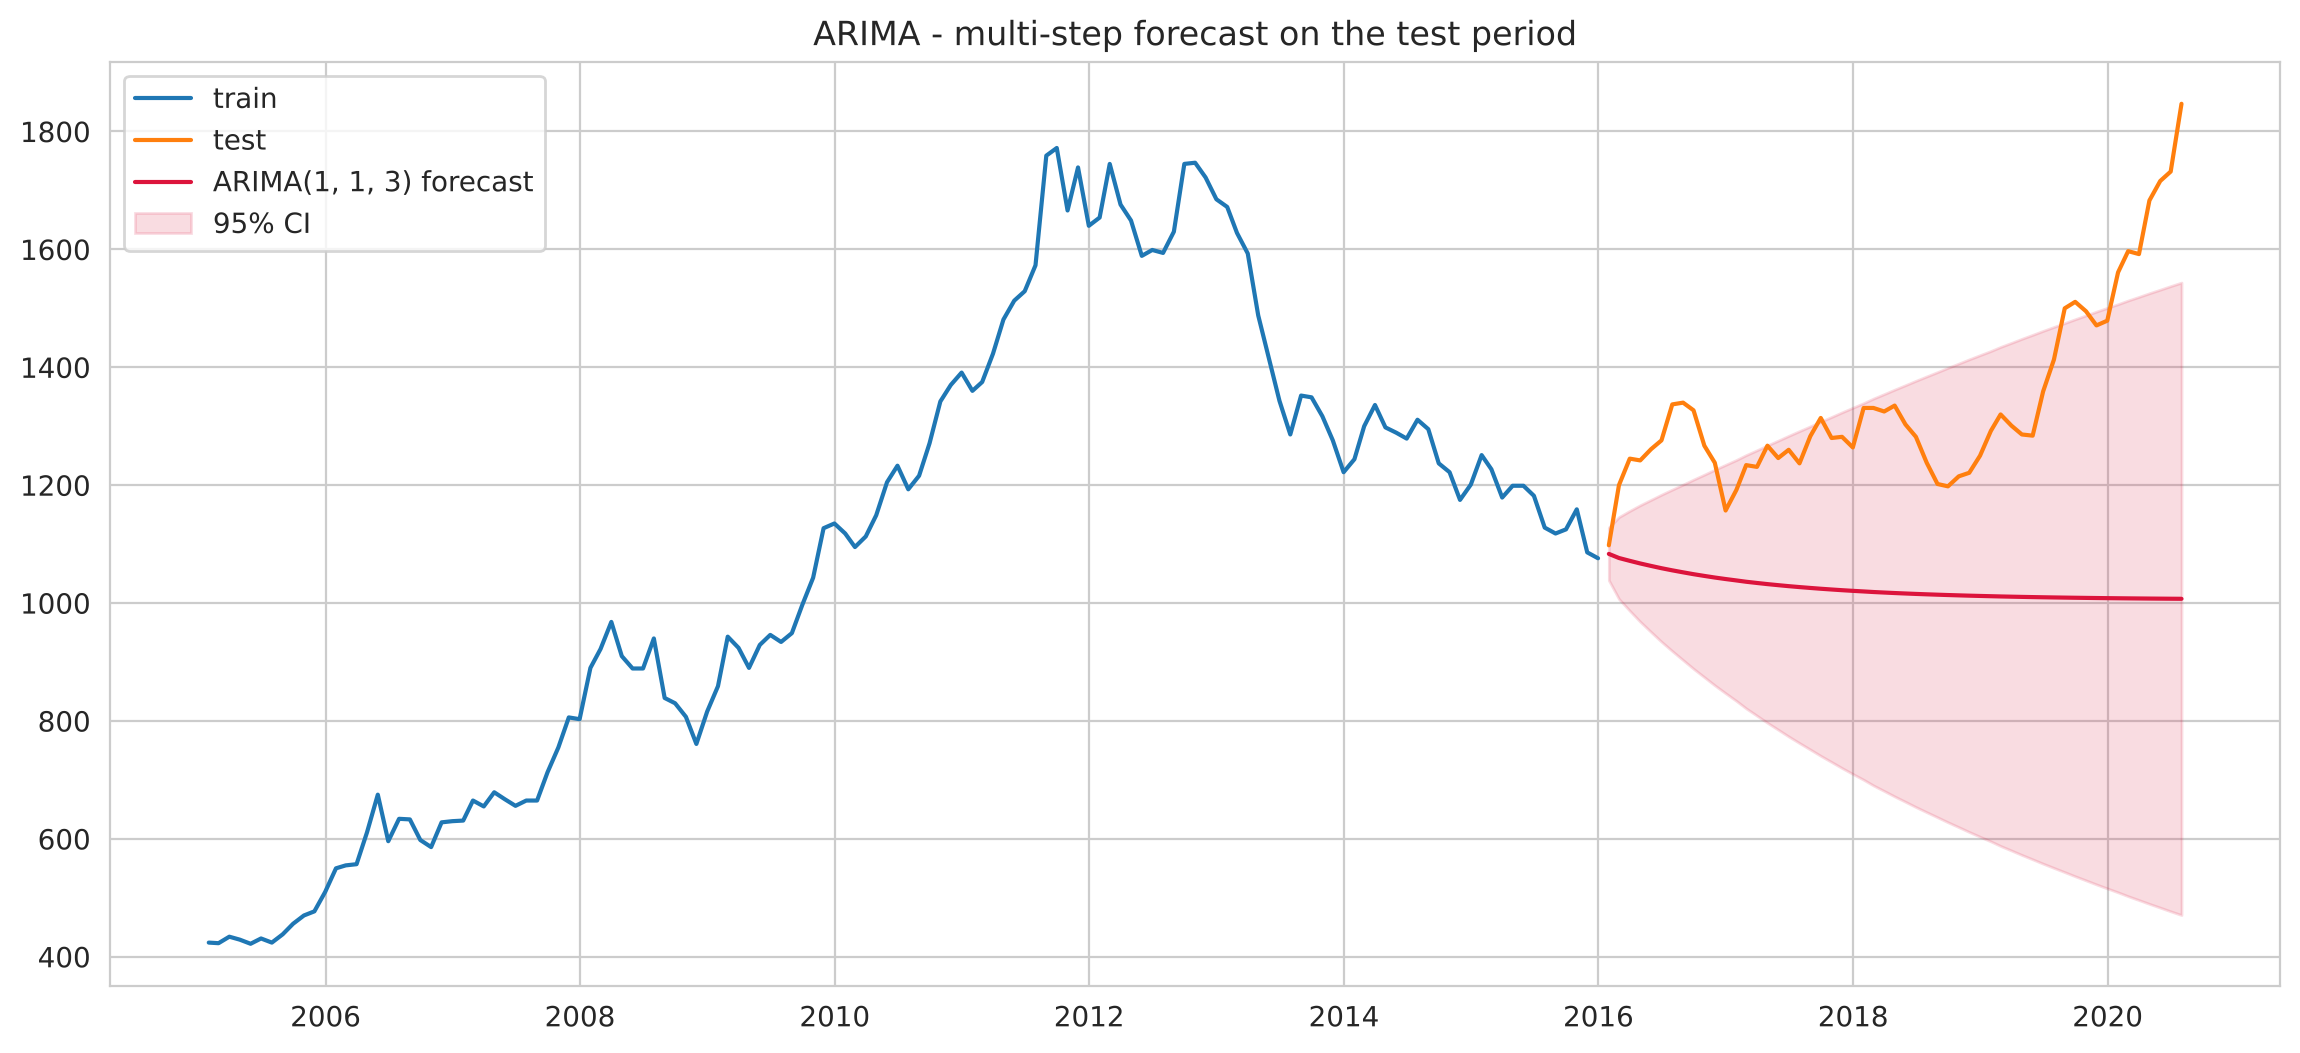

In [33]:
plt.figure(figsize=(14, 6))
plt.plot(y_train['2005':], label='train')
plt.plot(y_test, label='test')
plt.plot(arima_pred, label=f'ARIMA{best_arima_order} forecast', color='crimson')
plt.fill_between(arima_ci.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1], color='crimson', alpha=0.15, label='95% CI')
plt.title('ARIMA - multi-step forecast on the test period'); plt.legend(); save('arima_forecast'); plt.show()

### 3. SARIMA(p, 1, q)(P, D, Q, 12) - grid search on AIC
Monthly data -> seasonal period **s = 12**.

In [34]:
t0 = time.time()
sarima_results = []
for p, q, P, D, Q in itertools.product(range(3), range(3), range(2), range(2), range(2)):
    try:
        fit = SARIMAX(y_train, order=(p, 1, q), seasonal_order=(P, D, Q, 12)).fit(disp=False)
        sarima_results.append({'order': (p, 1, q), 'seasonal_order': (P, D, Q, 12), 'AIC': fit.aic})
    except Exception:
        continue

sarima_grid = pd.DataFrame(sarima_results).sort_values('AIC').reset_index(drop=True)
print(f'{len(sarima_grid)} models fitted in {time.time()-t0:.1f}s')
sarima_grid.head(5)

72 models fitted in 31.0s


,order,seasonal_order,AIC
0,"(1, 1, 1)","(1, 1, 1, 12)",7149.829037
1,"(1, 1, 1)","(0, 1, 1, 12)",7150.509723
2,"(1, 1, 2)","(1, 1, 1, 12)",7150.723730
3,"(2, 1, 1)","(1, 1, 1, 12)",7150.816114
4,"(1, 1, 2)","(0, 1, 1, 12)",7151.651611


In [35]:
best_sarima_order    = sarima_grid.loc[0, 'order']
best_sarima_seasonal = sarima_grid.loc[0, 'seasonal_order']
sarima_fit = SARIMAX(y_train, order=best_sarima_order, seasonal_order=best_sarima_seasonal).fit(disp=False)
print(sarima_fit.summary())

sarima_fc = sarima_fit.get_forecast(steps=len(y_test))
sarima_pred = sarima_fc.predicted_mean
sarima_ci = sarima_fc.conf_int(alpha=0.05)
sarima_pred.index = y_test.index; sarima_ci.index = y_test.index

                                     SARIMAX Results                                      
Dep. Variable:                              Price   No. Observations:                  792
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood               -3569.915
Date:                            Wed, 25 Nov 2026   AIC                           7149.829
Time:                                    10:47:54   BIC                           7173.119
Sample:                                01-31-1950   HQIC                          7158.787
                                     - 12-31-2015                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5421      0.051    -10.594      0.000      -0.642      -0.442
ma.L1          0.7224      0.043   

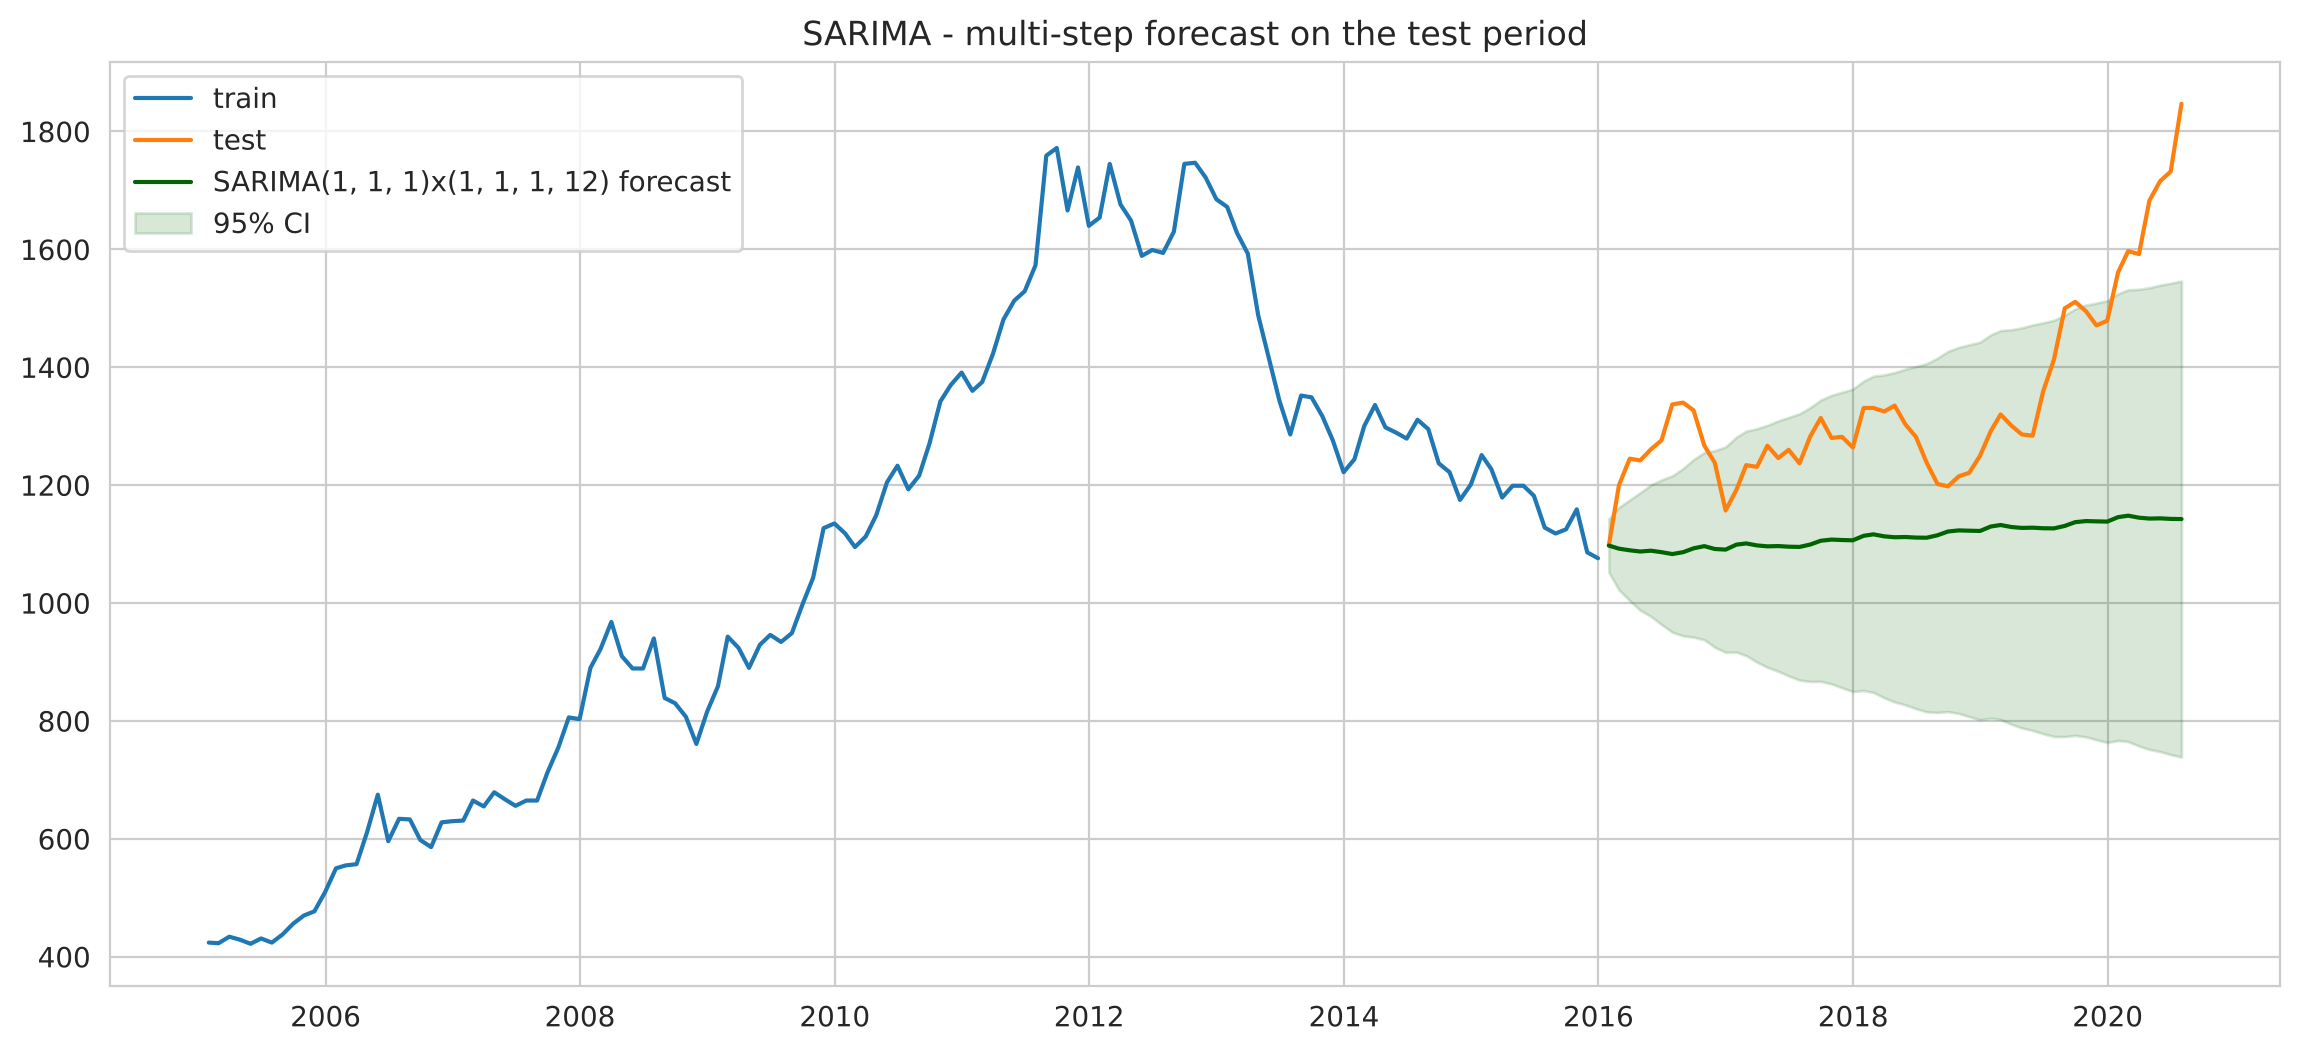

In [36]:
plt.figure(figsize=(14, 6))
plt.plot(y_train['2005':], label='train')
plt.plot(y_test, label='test')
plt.plot(sarima_pred, label=f'SARIMA{best_sarima_order}x{best_sarima_seasonal} forecast', color='darkgreen')
plt.fill_between(sarima_ci.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1], color='darkgreen', alpha=0.15, label='95% CI')
plt.title('SARIMA - multi-step forecast on the test period'); plt.legend(); save('sarima_forecast'); plt.show()

### 4. Residual diagnostics
A good model leaves residuals that look like white noise (no autocorrelation, roughly normal).

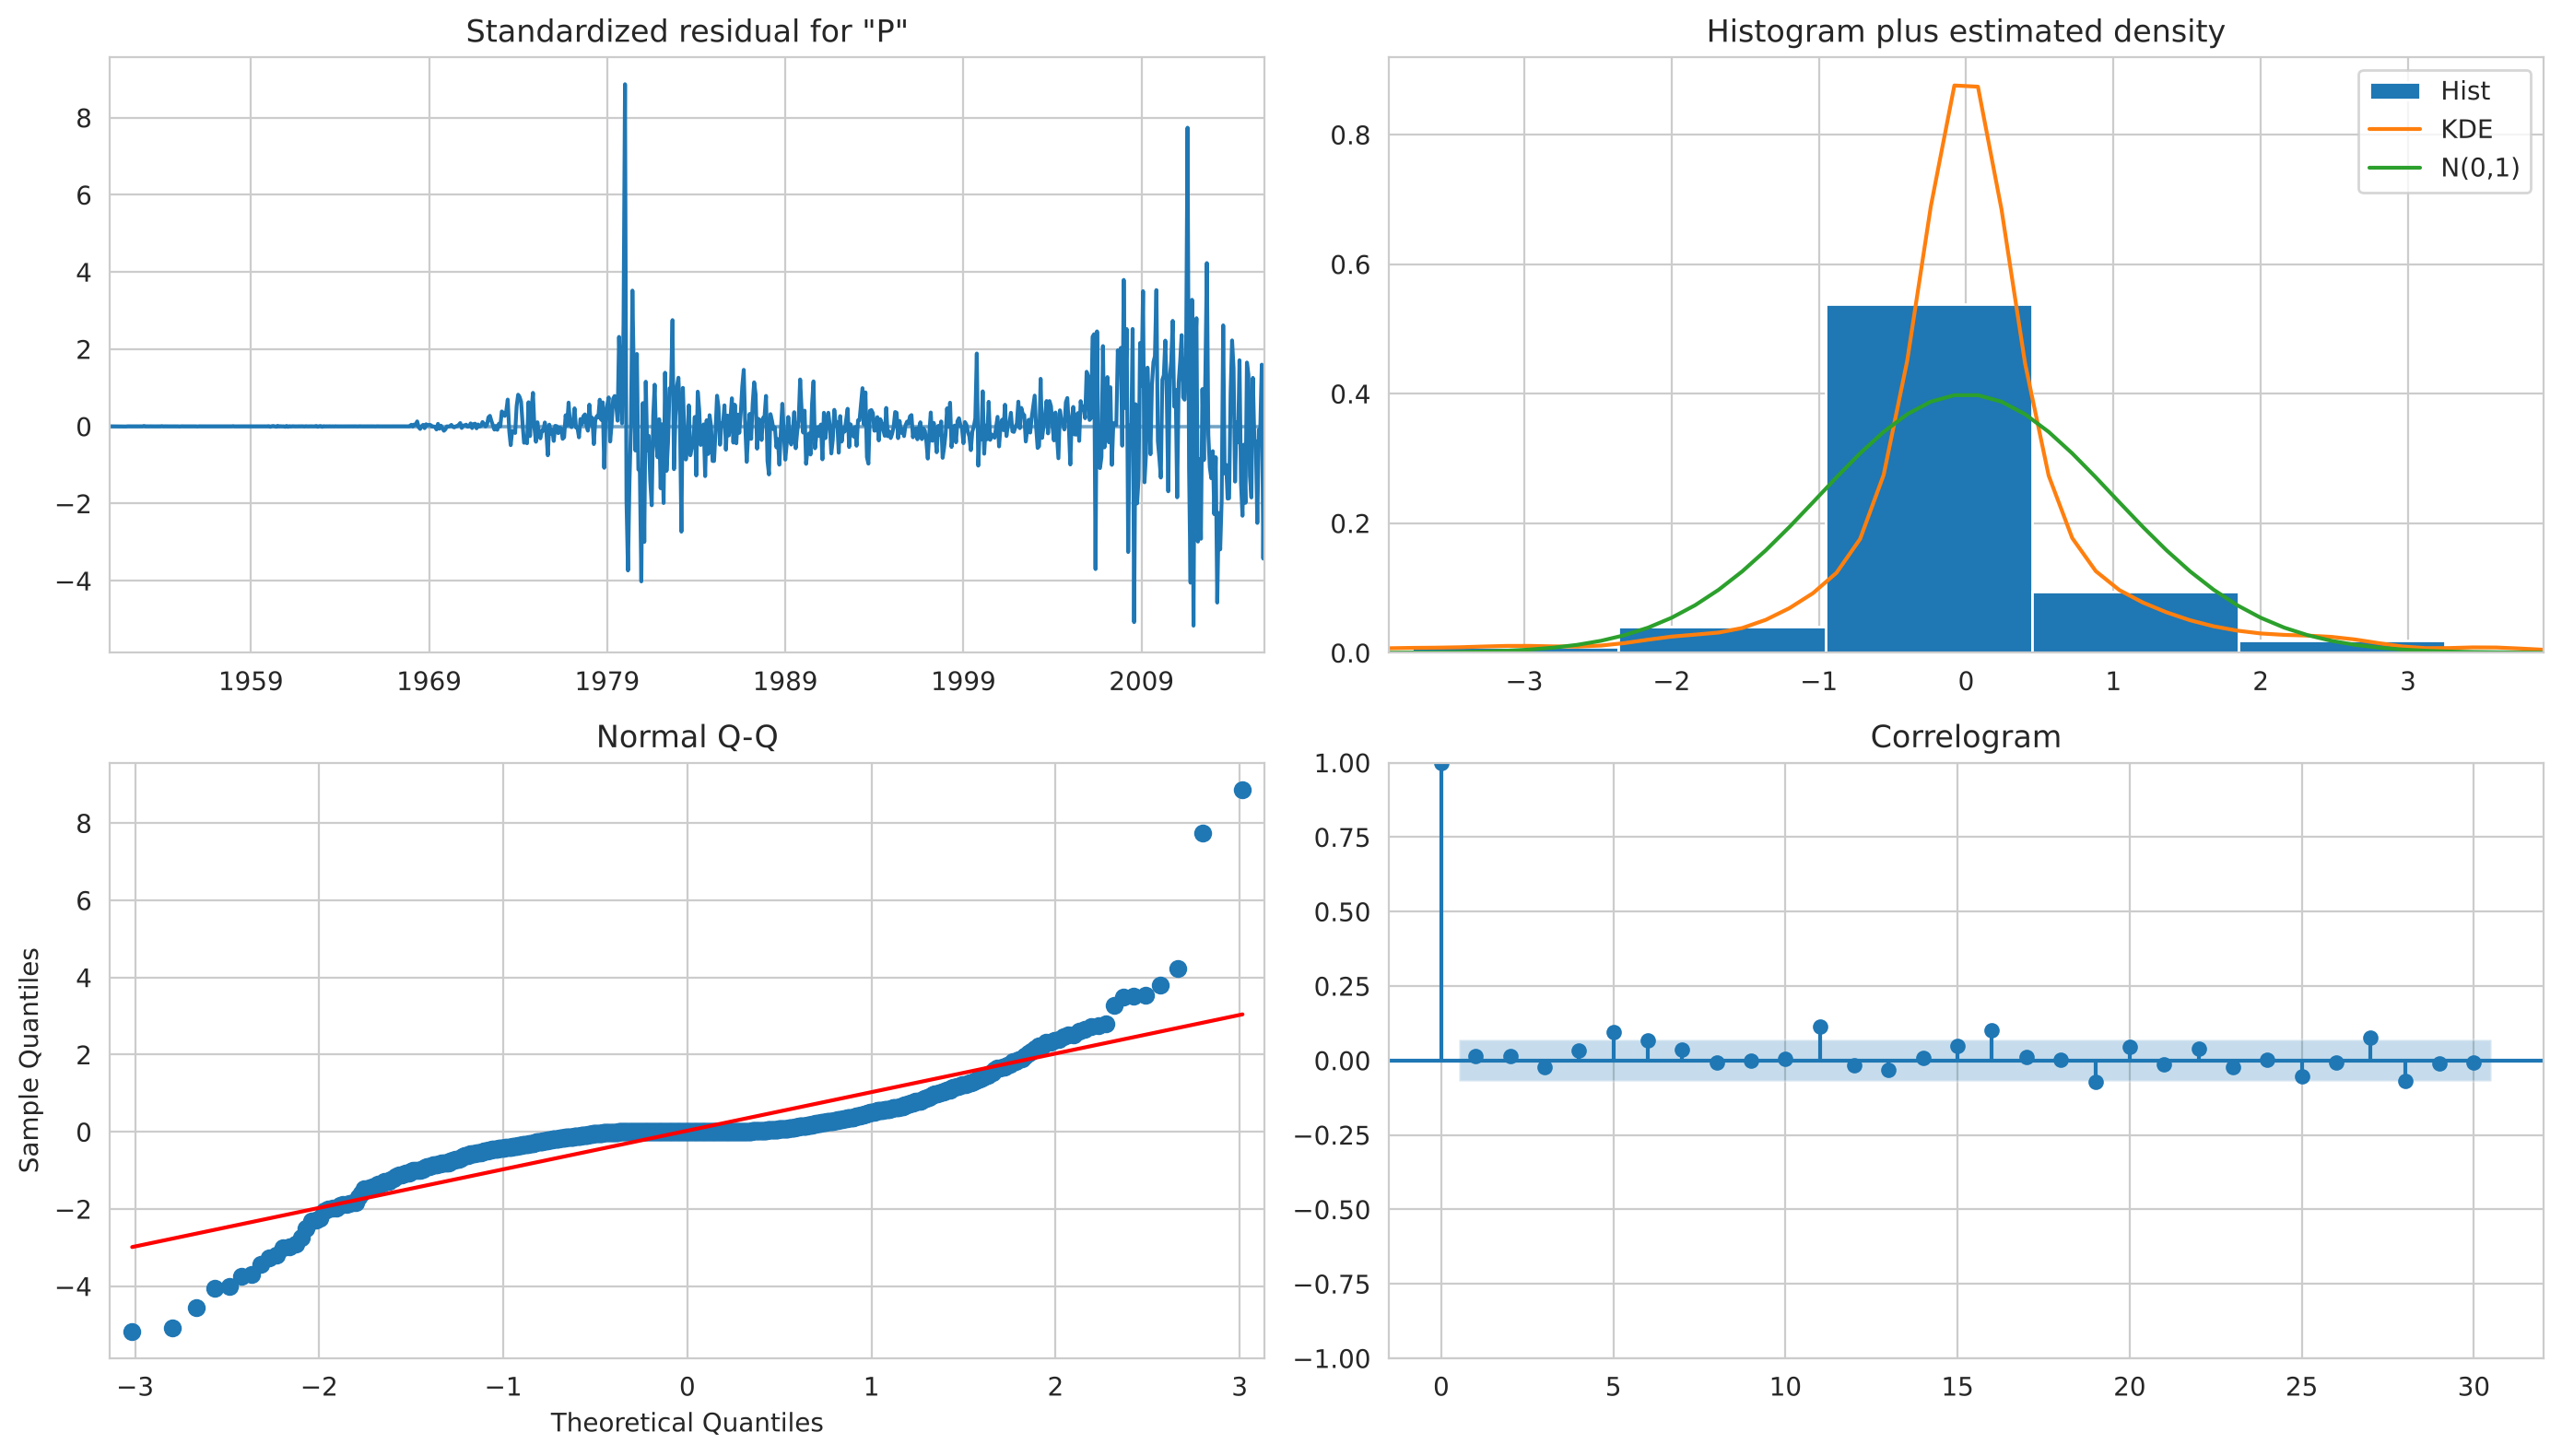

Ljung-Box p-values (p > 0.05 -> residuals ~ white noise)


,ARIMA,SARIMA
Ljung-Box lag,,
12,0.1983,0.024
24,0.1634,0.013


In [37]:
fig = sarima_fit.plot_diagnostics(figsize=(14, 8), lags=30)
plt.tight_layout(); save('sarima_diagnostics'); plt.show()

lb = pd.DataFrame({
    'ARIMA':  acorr_ljungbox(arima_fit.resid[13:],  lags=[12, 24], return_df=True)['lb_pvalue'],
    'SARIMA': acorr_ljungbox(sarima_fit.resid[13:], lags=[12, 24], return_df=True)['lb_pvalue'],
}).round(4)
lb.index.name = 'Ljung-Box lag'
print('Ljung-Box p-values (p > 0.05 -> residuals ~ white noise)')
lb

### 5. Accuracy comparison
Two evaluation protocols:
- **Multi-step (55 months ahead)**: the model forecasts the whole test period from the end of training - a hard, realistic long-horizon test.
- **Rolling one-step-ahead**: parameters stay fixed but each month the model sees the new observation, then forecasts the next month.

In [38]:
# ---------- Baselines ----------
naive_pred = pd.Series(y_train.iloc[-1], index=y_test.index)
drift_slope = (y_train.iloc[-1] - y_train.iloc[0]) / (len(y_train) - 1)
drift_pred  = pd.Series(y_train.iloc[-1] + drift_slope * np.arange(1, len(y_test) + 1), index=y_test.index)
lr_pred     = pd.Series(LR_test['forecast'].values, index=y_test.index)

multi = {
    'Linear regression (trend)': lr_pred,
    'Naive (last value)':        naive_pred,
    'Drift':                     drift_pred,
    f'ARIMA{best_arima_order}':  arima_pred,
    f'SARIMA{best_sarima_order}x{best_sarima_seasonal}': sarima_pred,
}

# ---------- Rolling one-step-ahead (fixed parameters, data appended month by month) ----------
arima_roll  = arima_fit.extend(y_test).get_prediction(start=y_test.index[0], end=y_test.index[-1]).predicted_mean
sarima_roll = sarima_fit.extend(y_test).get_prediction(start=y_test.index[0], end=y_test.index[-1]).predicted_mean
naive_roll  = y_test.shift(1).fillna(y_train.iloc[-1])

one_step = {
    'Naive (last value)':        naive_roll,
    f'ARIMA{best_arima_order}':  arima_roll,
    f'SARIMA{best_sarima_order}x{best_sarima_seasonal}': sarima_roll,
}

def score(preds):
    return pd.DataFrame({
        name: {'MAPE (%)': mape_pct(y_test, p), 'RMSE': rmse(y_test, p), 'MAE': mae(y_test, p)}
        for name, p in preds.items()
    }).T.sort_values('MAPE (%)')

print('Multi-step (55 months ahead)');  display(score(multi))
print('Rolling one-step-ahead');        display(score(one_step))

Multi-step (55 months ahead)


,MAPE (%),RMSE,MAE
"SARIMA(1, 1, 1)x(1, 1, 1, 12)",16.03,267.23,226.68
Drift,16.15,267.63,228.01
Naive (last value),18.81,306.89,264.87
"ARIMA(1, 1, 3)",22.53,356.49,315.30
Linear regression (trend),29.78,431.78,408.61


Rolling one-step-ahead


,MAPE (%),RMSE,MAE
"SARIMA(1, 1, 1)x(1, 1, 1, 12)",2.21,40.48,29.80
"ARIMA(1, 1, 3)",2.32,41.30,31.17
Naive (last value),2.40,42.66,32.53


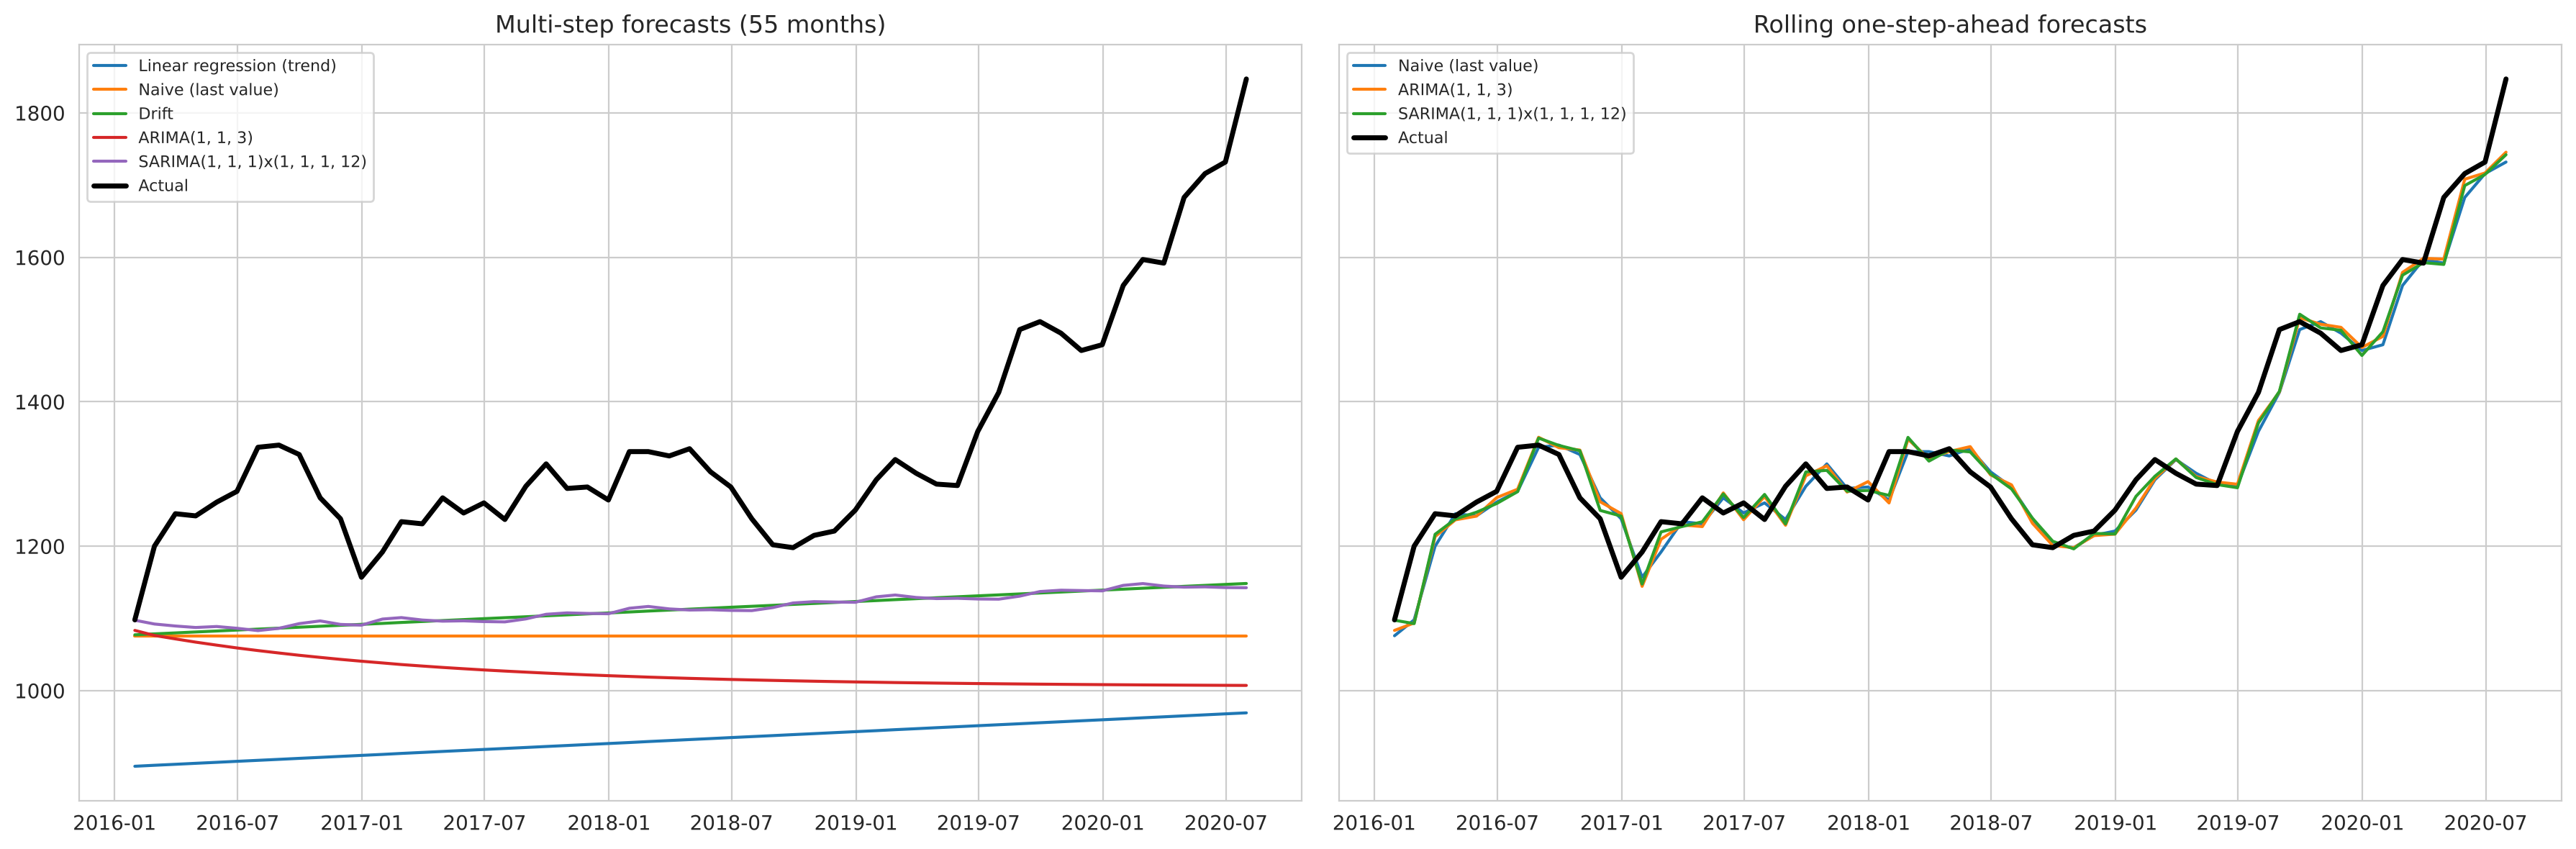

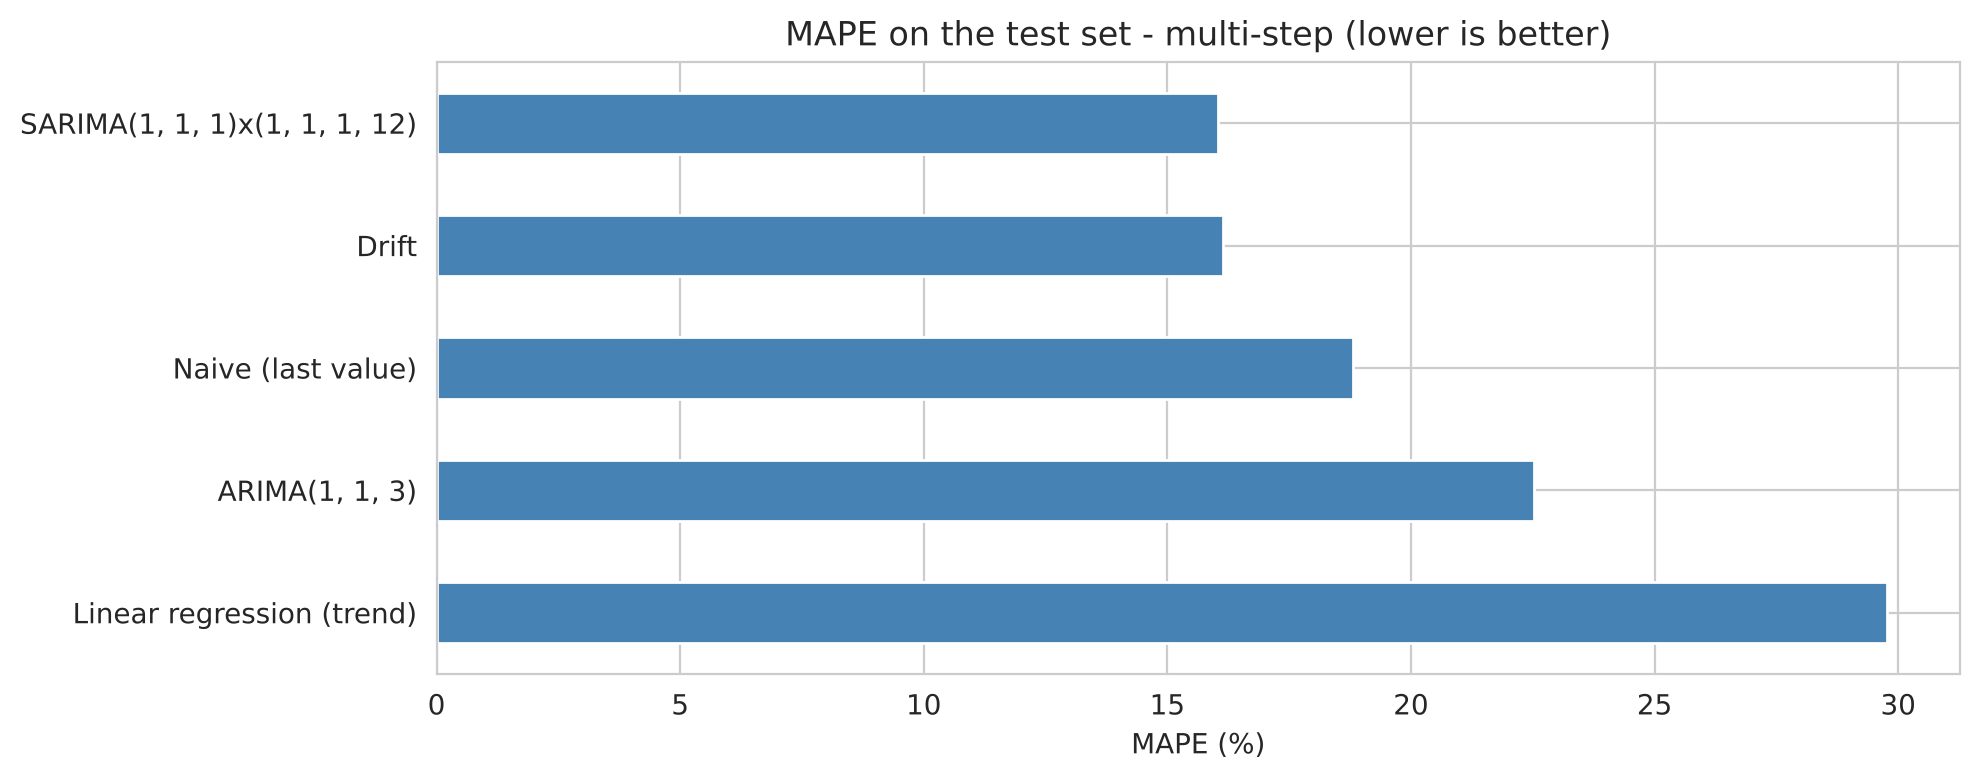

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
for name, p in multi.items():
    axes[0].plot(p, label=name)
axes[0].plot(y_test, color='black', lw=2.5, label='Actual'); axes[0].set_title('Multi-step forecasts (55 months)'); axes[0].legend(fontsize=8)
for name, p in one_step.items():
    axes[1].plot(p, label=name)
axes[1].plot(y_test, color='black', lw=2.5, label='Actual'); axes[1].set_title('Rolling one-step-ahead forecasts'); axes[1].legend(fontsize=8)
plt.tight_layout(); save('model_comparison'); plt.show()

score_multi = score(multi)
ax = score_multi['MAPE (%)'].sort_values(ascending=False).plot(kind='barh', figsize=(10, 4), color='steelblue')
ax.set_title('MAPE on the test set - multi-step (lower is better)'); ax.set_xlabel('MAPE (%)')
plt.tight_layout(); save('mape_comparison'); plt.show()

### 6. Final model - refit on all data and forecast the next 24 months

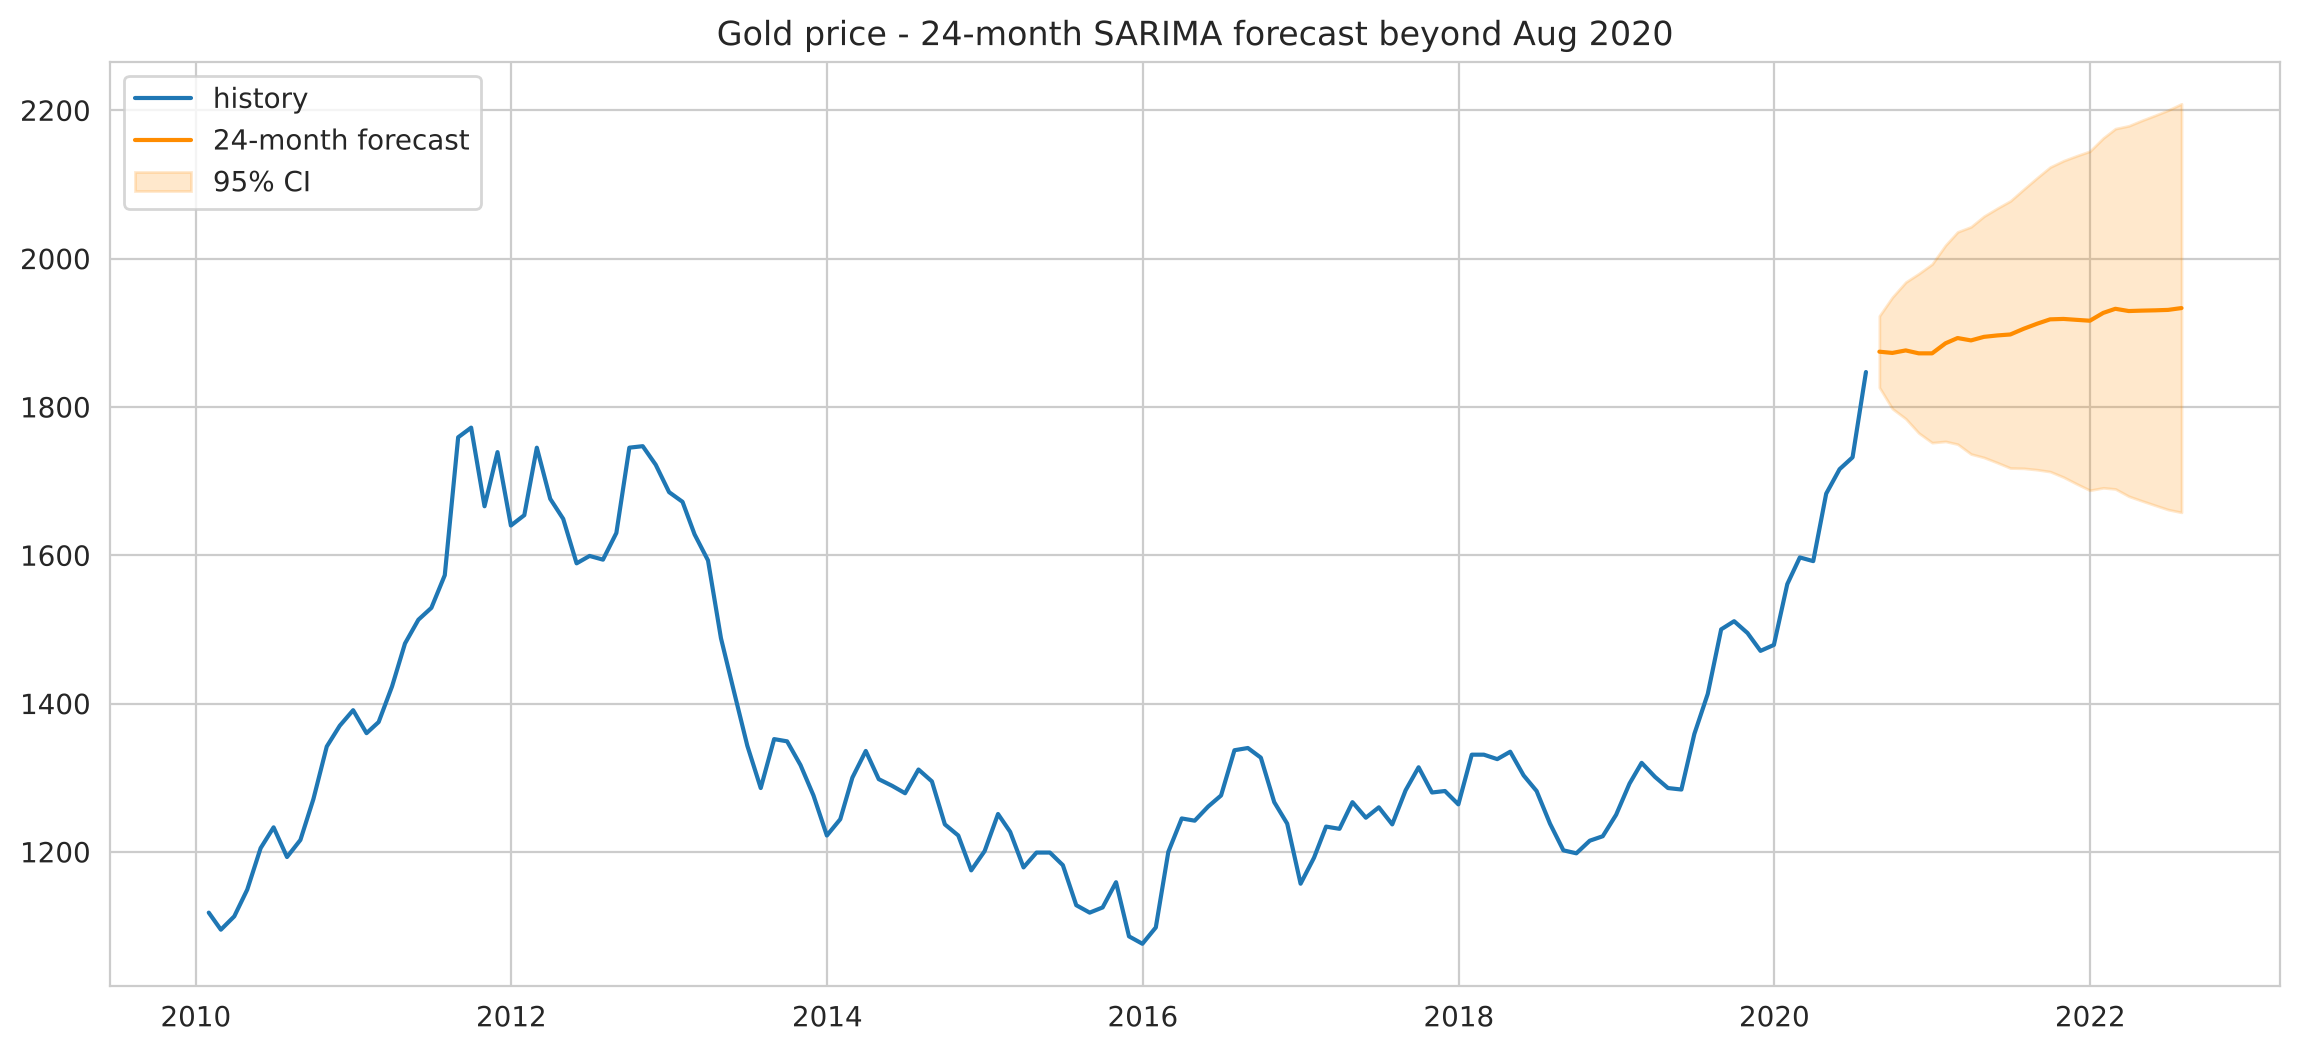

,forecast,lower,upper
2020-08-31,1874.4,1826.2,1922.7
2020-09-30,1872.8,1797.6,1947.9
2020-10-31,1876.1,1784.0,1968.3
2020-11-30,1872.2,1764.8,1979.7
2020-12-31,1872.2,1751.8,1992.6
2021-01-31,1885.7,1753.4,2018.0


In [40]:
final_model = SARIMAX(df['Price'], order=best_sarima_order, seasonal_order=best_sarima_seasonal).fit(disp=False)
future = final_model.get_forecast(steps=24)
future_mean = future.predicted_mean
future_ci = future.conf_int(alpha=0.05)

plt.figure(figsize=(14, 6))
plt.plot(df['Price']['2010':], label='history')
plt.plot(future_mean, color='darkorange', label='24-month forecast')
plt.fill_between(future_ci.index, future_ci.iloc[:, 0], future_ci.iloc[:, 1], color='darkorange', alpha=0.2, label='95% CI')
plt.title('Gold price - 24-month SARIMA forecast beyond Aug 2020'); plt.legend(); save('future_forecast'); plt.show()

future_mean.round(1).to_frame('forecast').assign(lower=future_ci.iloc[:, 0].round(1), upper=future_ci.iloc[:, 1].round(1)).head(6)

### Conclusions
- Gold is **non-stationary** (unit root) - one difference is required (d = 1).
- Seasonality is weak on this series; compare the SARIMA gain over ARIMA in the tables above before claiming it matters.
- Over a 55-month horizon every statistical model is limited, because the 2016-2020 rally is a structural move that no model trained on data up to 2015 can anticipate - the confidence intervals widen accordingly.
- Rolling one-step-ahead forecasts are far more accurate, which is the realistic way these models are used in production (re-fit / update regularly).